In [3]:
!pip install -q nltk gensim transformers sentencepiece accelerate


In [4]:
import os
import re
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

import nltk

from collections import Counter

from sklearn.datasets import fetch_20newsgroups
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Dense,
    Dropout,
    Embedding,
    Conv1D,
    GlobalMaxPooling1D,
    SimpleRNN,
    GRU,
    LSTM,
    Bidirectional,
    GlobalAveragePooling1D
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping

from gensim.models import Word2Vec, FastText

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [5]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [6]:
nltk.download("stopwords")
nltk.download("punkt")
nltk.download("punkt_tab")

from nltk.corpus import stopwords

STOPWORDS = set(stopwords.words("english"))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [7]:
train_original = fetch_20newsgroups(
    subset="train",
    remove=()
)

test_original = fetch_20newsgroups(
    subset="test",
    remove=()
)

texts = np.array(
    train_original.data + test_original.data,
    dtype=object
)

labels = np.array(
    list(train_original.target) +
    list(test_original.target)
)

CLASS_NAMES = train_original.target_names

NUM_CLASSES = len(CLASS_NAMES)

print("Total documents:", len(texts))
print("Number of classes:", NUM_CLASSES)

for i, name in enumerate(CLASS_NAMES):
    print(i, "->", name)

Total documents: 18846
Number of classes: 20
0 -> alt.atheism
1 -> comp.graphics
2 -> comp.os.ms-windows.misc
3 -> comp.sys.ibm.pc.hardware
4 -> comp.sys.mac.hardware
5 -> comp.windows.x
6 -> misc.forsale
7 -> rec.autos
8 -> rec.motorcycles
9 -> rec.sport.baseball
10 -> rec.sport.hockey
11 -> sci.crypt
12 -> sci.electronics
13 -> sci.med
14 -> sci.space
15 -> soc.religion.christian
16 -> talk.politics.guns
17 -> talk.politics.mideast
18 -> talk.politics.misc
19 -> talk.religion.misc


In [8]:
X_train, X_temp, y_train, y_temp = train_test_split(
    texts,
    labels,
    test_size=0.30,
    random_state=SEED,
    stratify=labels
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

print(
    "Percentages:",
    len(X_train) / len(texts) * 100,
    len(X_val) / len(texts) * 100,
    len(X_test) / len(texts) * 100
)

Train: 13192
Validation: 2827
Test: 2827
Percentages: 69.99893876684708 15.000530616576462 15.000530616576462


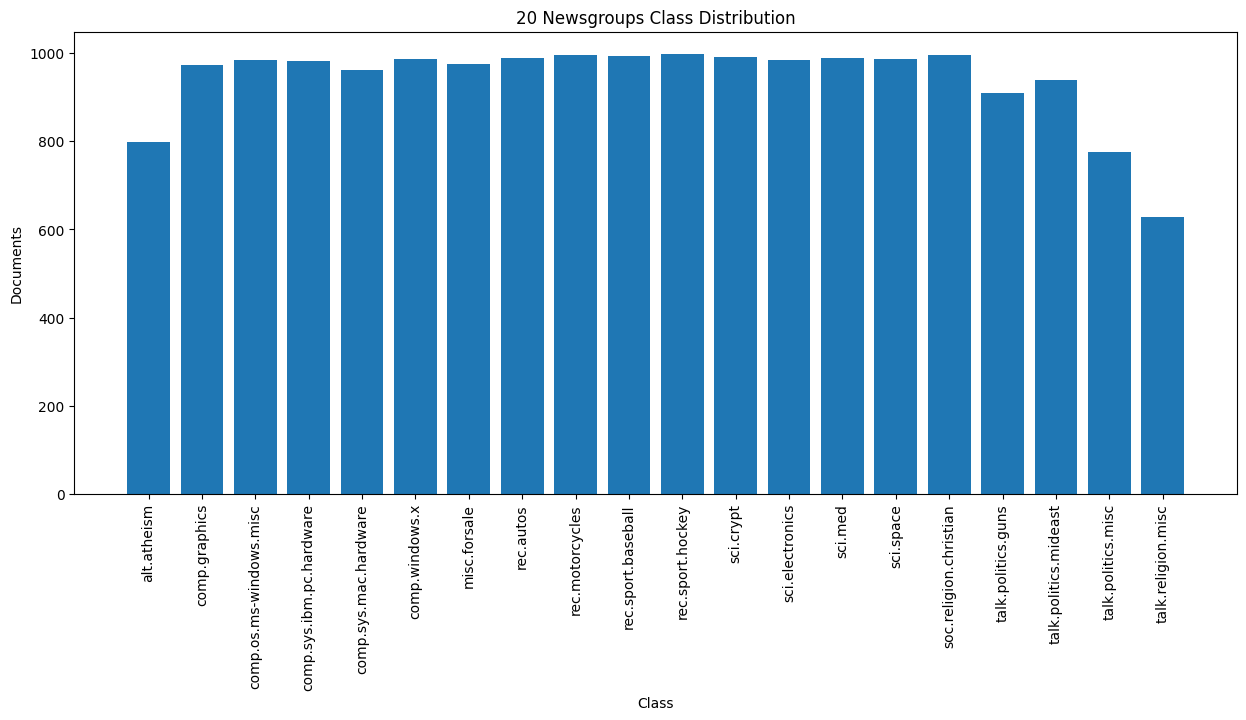

In [9]:
distribution = pd.Series(labels).value_counts().sort_index()

plt.figure(figsize=(15, 6))

plt.bar(
    CLASS_NAMES,
    distribution.values
)

plt.xticks(rotation=90)
plt.xlabel("Class")
plt.ylabel("Documents")
plt.title("20 Newsgroups Class Distribution")
plt.show()

In [10]:
def clean_text(text):

    text = str(text)

    # Remove email headers
    text = re.sub(
        r'(?m)^(From|Subject|Organization|Lines|NNTP-Posting-Host|Reply-To|X-.*?):.*$',
        ' ',
        text
    )

    # Remove URLs
    text = re.sub(
        r'http\S+|www\S+',
        ' ',
        text
    )

    # Remove email addresses
    text = re.sub(
        r'\S+@\S+',
        ' ',
        text
    )

    # Lowercase
    text = text.lower()

    # Keep alphabetic words
    text = re.sub(
        r'[^a-z\s]',
        ' ',
        text
    )

    # Multiple spaces
    text = re.sub(
        r'\s+',
        ' ',
        text
    ).strip()

    # Tokenization
    tokens = text.split()

    # Remove stopwords
    tokens = [
        word for word in tokens
        if word not in STOPWORDS
    ]

    return " ".join(tokens)

In [11]:
X_train_clean = [
    clean_text(x)
    for x in X_train
]

X_val_clean = [
    clean_text(x)
    for x in X_val
]

X_test_clean = [
    clean_text(x)
    for x in X_test
]

print("Original:")
print(X_train[0][:1000])

print("\n\nClean:")
print(X_train_clean[0][:1000])

Original:
From: kbos@carina.unm.edu (K. Mitchell Bose)
Subject: Re: ESPN and Expansion
Organization: University of New Mexico, Albuquerque
Lines: 38
NNTP-Posting-Host: carina.unm.edu

In article <C5109u.7C0@ucdavis.edu> itlm013@dale.ucdavis.edu (Donnie Trump) writes:
>I was watching Peter Gammons on ESPN last night, and he's got me a little
>confused.
>
>While talking about expansion, he started mentioning people who might benefit
>from the fringe players they'll be facing: McGriff hitting 50 home runs,
>Sheffield getting 150 rbi's, and Glavine winning 25 games.  This was,
>of course, all in reference to what happened the *other* times that baseball
>has expanded (early 60's, late 60's, late 70's).
>
>What really confused me, though, was the mention of *AL* players who would
>do well next year.  Specifically, Roger Clemens winning 25 games, and the
>likes of McGwire and Gonzalez hitting 50 home runs.
>
>My question is:  How in the hell will the Rockies/Marlins help the AL?  The
>last t

In [12]:
def remove_empty_texts(texts, labels):

    mask = np.array([
        len(text.strip()) > 0
        for text in texts
    ])

    return (
        np.array(texts)[mask],
        np.array(labels)[mask]
    )


X_train_clean, y_train = remove_empty_texts(
    X_train_clean,
    y_train
)

X_val_clean, y_val = remove_empty_texts(
    X_val_clean,
    y_val
)

X_test_clean, y_test = remove_empty_texts(
    X_test_clean,
    y_test
)

print(len(X_train_clean))
print(len(X_val_clean))
print(len(X_test_clean))

13184
2825
2825


In [13]:
RESULTS = []


def evaluate_model(
    model_name,
    y_true,
    y_pred,
    show_cm=True
):

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    RESULTS.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

    print("\n================================")
    print(model_name)
    print("================================")
    print("Accuracy :", accuracy)
    print("Precision:", precision)
    print("Recall   :", recall)
    print("F1 Score :", f1)

    if show_cm:

        cm = confusion_matrix(
            y_true,
            y_pred
        )

        plt.figure(figsize=(12, 10))

        sns.heatmap(
            cm,
            cmap="Blues",
            xticklabels=CLASS_NAMES,
            yticklabels=CLASS_NAMES
        )

        plt.xlabel("Predicted")
        plt.ylabel("Actual")
        plt.title(f"Confusion Matrix — {model_name}")
        plt.xticks(rotation=90)
        plt.yticks(rotation=0)
        plt.show()

    return accuracy, precision, recall, f1

In [14]:
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

X_train_tfidf = tfidf.fit_transform(
    X_train_clean
)

X_val_tfidf = tfidf.transform(
    X_val_clean
)

X_test_tfidf = tfidf.transform(
    X_test_clean
)

print(
    "Vocabulary size:",
    len(tfidf.vocabulary_)
)

print(
    "Train shape:",
    X_train_tfidf.shape
)


Vocabulary size: 10000
Train shape: (13184, 10000)


In [15]:
ann_model = Sequential([

    Dense(
        256,
        activation="relu",
        input_shape=(X_train_tfidf.shape[1],)
    ),

    Dropout(0.4),

    Dense(
        128,
        activation="relu"
    ),

    Dropout(0.3),

    Dense(
        NUM_CLASSES,
        activation="softmax"
    )
])

ann_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │     2,560,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 20)             │         2,580 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,595,732 (9.90 MB)

 Trainable params: 2,595,732 (9.90 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
nn_history = ann_model.fit(
    X_train_tfidf.toarray(),
    y_train,

    validation_data=(
        X_val_tfidf.toarray(),
        y_val
    ),

    epochs=15,
    batch_size=128,

    callbacks=[
        EarlyStopping(
            patience=3,
            restore_best_weights=True
        )
    ]
)


Epoch 1/15
103/103 ━━━━━━━━━━━━━━━━━━━━ 7s 29ms/step - accuracy: 0.4710 - loss: 2.2359 - val_accuracy: 0.7908 - val_loss: 1.0483
Epoch 2/15
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.8226 - loss: 0.7086 - val_accuracy: 0.8389 - val_loss: 0.5708
Epoch 3/15
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.9182 - loss: 0.3312 - val_accuracy: 0.8531 - val_loss: 0.4850
Epoch 4/15
103/103 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9585 - loss: 0.1879 - val_accuracy: 0.8588 - val_loss: 0.4597
Epoch 5/15
103/103 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9777 - loss: 0.1119 - val_accuracy: 0.8619 - val_loss: 0.4626
Epoch 6/15
103/103 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9861 - loss: 0.0748 - val_accuracy: 0.8598 - val_loss: 0.4768
Epoch 7/15
103/103 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9912 - loss: 0.0494 - val_accuracy: 0.8591 - val_loss: 0.4875


23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step

ANN + TF-IDF
Accuracy : 0.8789380530973452
Precision: 0.8808872898037047
Recall   : 0.8789380530973452
F1 Score : 0.879240301029888


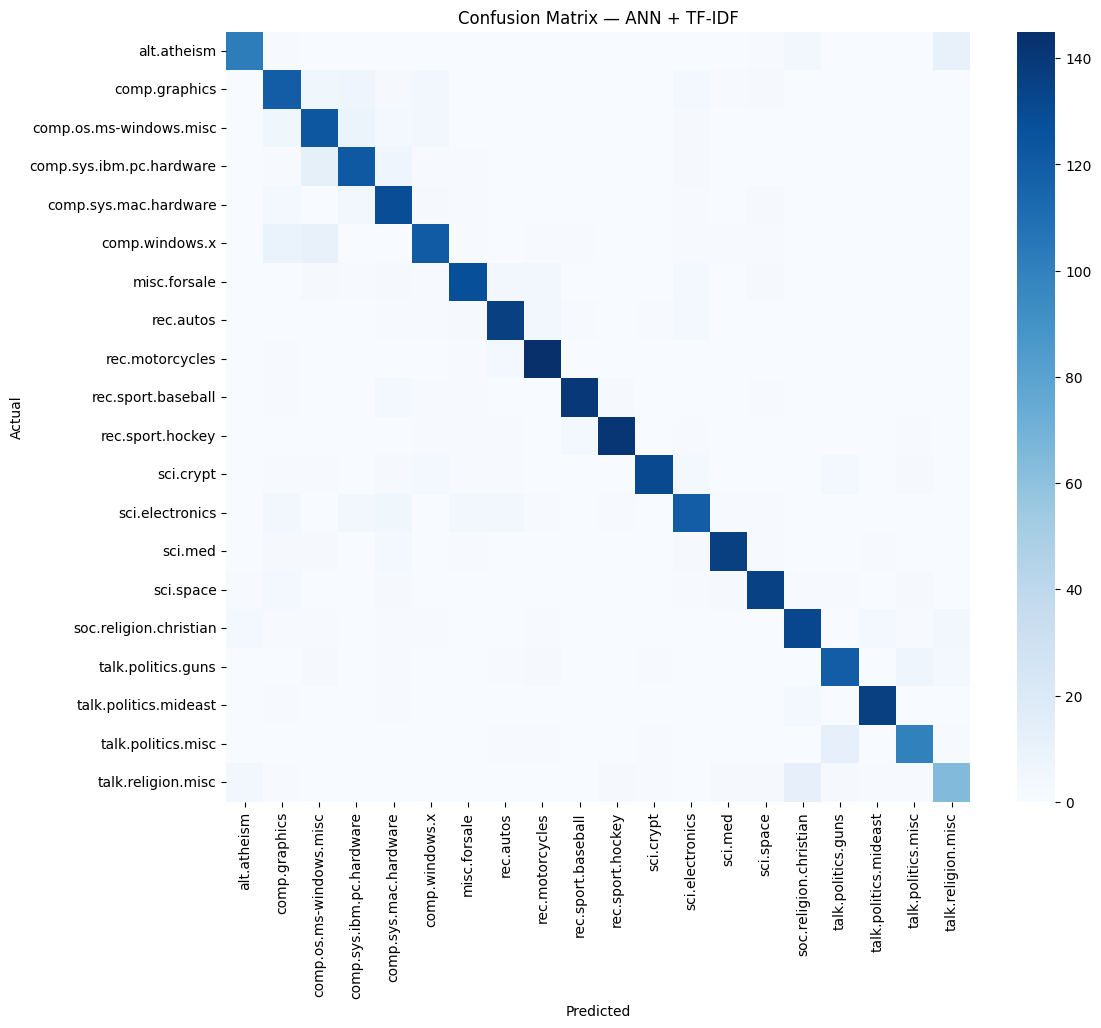

(0.8789380530973452, 0.8808872898037047, 0.8789380530973452, 0.879240301029888)

In [17]:
ann_probs = ann_model.predict(
    X_test_tfidf.toarray(),
    batch_size=128
)

ann_pred = np.argmax(
    ann_probs,
    axis=1
)

evaluate_model(
    "ANN + TF-IDF",
    y_test,
    ann_pred
)

In [18]:
MAX_WORDS = 30000
MAX_LEN = 300

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(
    X_train_clean
)

X_train_seq = tokenizer.texts_to_sequences(
    X_train_clean
)

X_val_seq = tokenizer.texts_to_sequences(
    X_val_clean
)

X_test_seq = tokenizer.texts_to_sequences(
    X_test_clean
)

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_val_pad = pad_sequences(
    X_val_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

VOCAB_SIZE = min(
    MAX_WORDS,
    len(tokenizer.word_index) + 1
)

print("Vocabulary:", VOCAB_SIZE)
print("Sequence shape:", X_train_pad.shape)


Vocabulary: 30000
Sequence shape: (13184, 300)


In [19]:
def build_cnn(
    kernel_size=3,
    filters=128
):

    model = Sequential([

        Embedding(
            VOCAB_SIZE,
            128,
            input_length=MAX_LEN
        ),

        Conv1D(
            filters=filters,
            kernel_size=kernel_size,
            activation="relu"
        ),

        GlobalMaxPooling1D(),

        Dense(
            128,
            activation="relu"
        ),

        Dropout(0.4),

        Dense(
            NUM_CLASSES,
            activation="softmax"
        )
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


Training CNN kernel: 3
Epoch 1/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 13s 54ms/step - accuracy: 0.2241 - loss: 2.7868 - val_accuracy: 0.5338 - val_loss: 2.1058
Epoch 2/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.6208 - loss: 1.4202 - val_accuracy: 0.7366 - val_loss: 0.9773
Epoch 3/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.8243 - loss: 0.6577 - val_accuracy: 0.7943 - val_loss: 0.7034
Epoch 4/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.9257 - loss: 0.3031 - val_accuracy: 0.8219 - val_loss: 0.6022
Epoch 5/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9721 - loss: 0.1393 - val_accuracy: 0.8343 - val_loss: 0.5721
Epoch 6/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.9865 - loss: 0.0701 - val_accuracy: 0.8382 - val_loss: 0.5703
Epoch 7/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.9951 - loss: 0.0405 - val_accuracy: 0.8389 - val_loss: 0.5858
Epoch 8/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.9961 

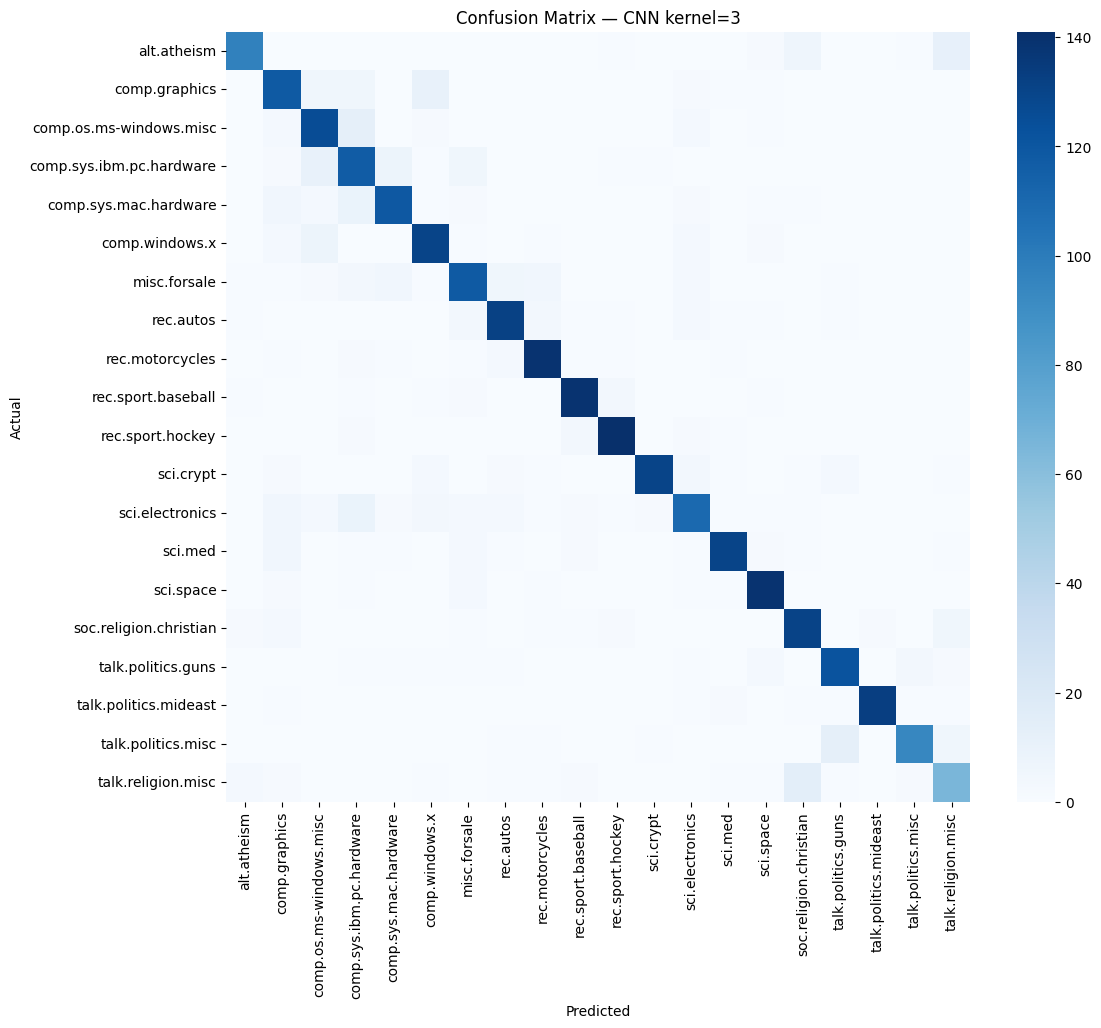


Training CNN kernel: 5
Epoch 1/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 12s 42ms/step - accuracy: 0.1787 - loss: 2.8580 - val_accuracy: 0.4722 - val_loss: 2.2543
Epoch 2/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - accuracy: 0.5800 - loss: 1.5244 - val_accuracy: 0.7221 - val_loss: 1.0245
Epoch 3/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.8240 - loss: 0.6528 - val_accuracy: 0.8074 - val_loss: 0.6808
Epoch 4/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.9380 - loss: 0.2663 - val_accuracy: 0.8343 - val_loss: 0.5836
Epoch 5/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.9801 - loss: 0.1041 - val_accuracy: 0.8481 - val_loss: 0.5655
Epoch 6/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9923 - loss: 0.0533 - val_accuracy: 0.8488 - val_loss: 0.5710
Epoch 7/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.9954 - loss: 0.0330 - val_accuracy: 0.8488 - val_loss: 0.5892
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 67ms/step

CNN kernel=5
Accuracy : 0.86548

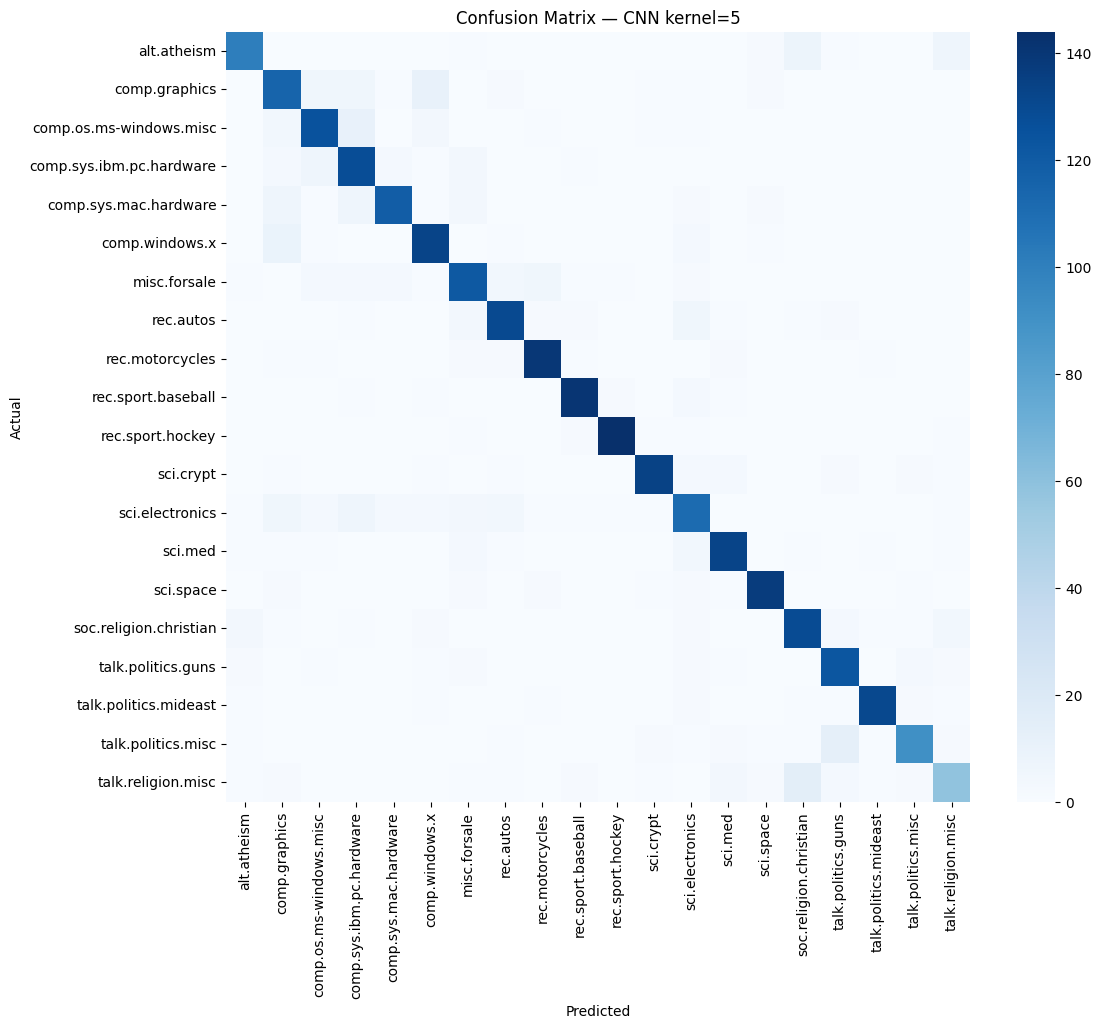


Training CNN kernel: 7
Epoch 1/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 11s 38ms/step - accuracy: 0.1641 - loss: 2.8889 - val_accuracy: 0.4673 - val_loss: 2.3889
Epoch 2/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.5824 - loss: 1.5113 - val_accuracy: 0.7278 - val_loss: 0.9692
Epoch 3/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.8274 - loss: 0.6174 - val_accuracy: 0.8071 - val_loss: 0.6627
Epoch 4/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.9399 - loss: 0.2446 - val_accuracy: 0.8251 - val_loss: 0.5866
Epoch 5/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.9803 - loss: 0.1017 - val_accuracy: 0.8297 - val_loss: 0.5877
Epoch 6/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.9915 - loss: 0.0550 - val_accuracy: 0.8326 - val_loss: 0.6026
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step

CNN kernel=7
Accuracy : 0.8598230088495575
Precision: 0.8646174403952257
Recall   : 0.8598230088495575
F1 Score : 0.8608644094283251


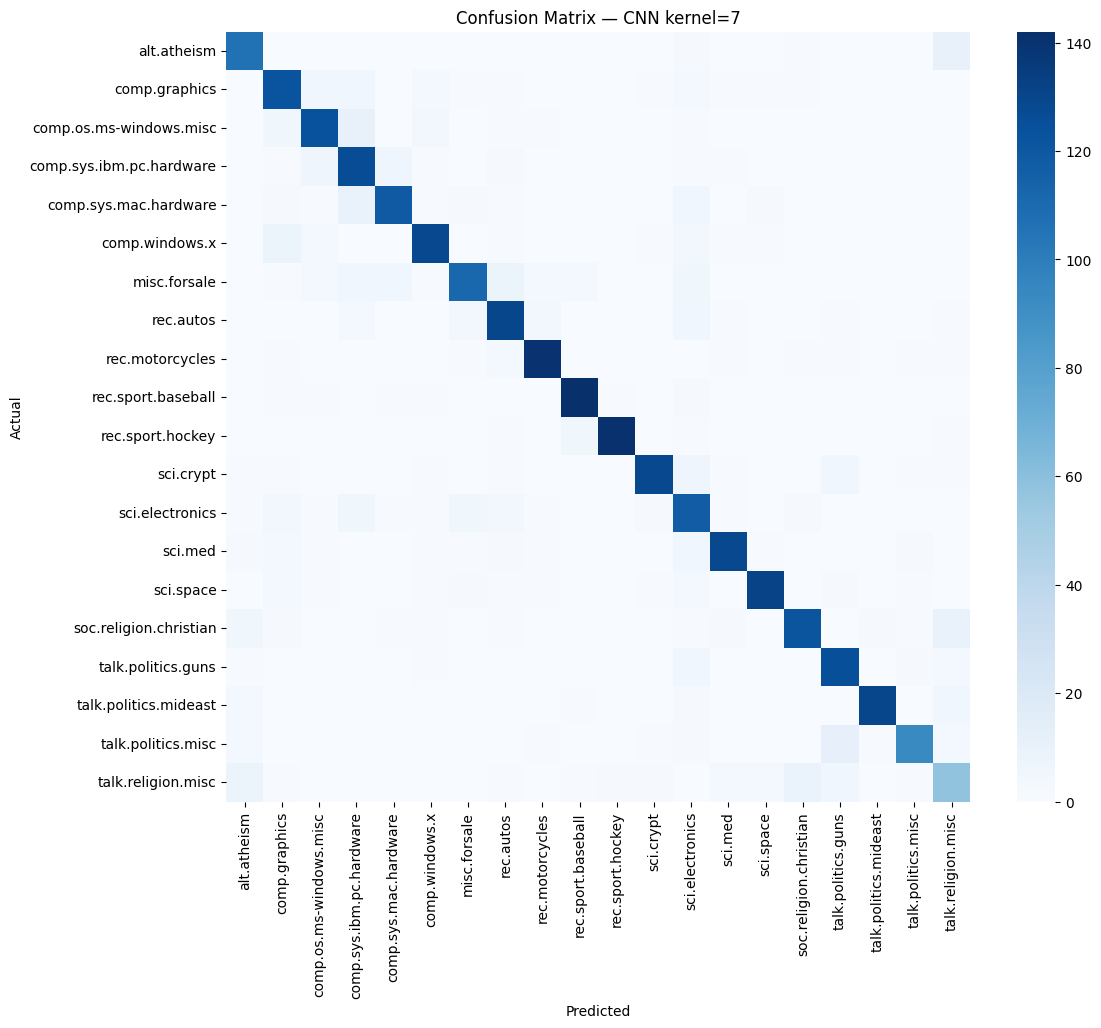

In [20]:
cnn_models = {}

for kernel in [3, 5, 7]:

    print("\nTraining CNN kernel:", kernel)

    model = build_cnn(
        kernel_size=kernel,
        filters=128
    )

    model.fit(
        X_train_pad,
        y_train,

        validation_data=(
            X_val_pad,
            y_val
        ),

        epochs=10,
        batch_size=128,

        callbacks=[
            EarlyStopping(
                patience=2,
                restore_best_weights=True
            )
        ],

        verbose=1
    )

    cnn_models[kernel] = model

    probs = model.predict(
        X_test_pad,
        batch_size=128
    )

    pred = np.argmax(
        probs,
        axis=1
    )

    evaluate_model(
        f"CNN kernel={kernel}",
        y_test,
        pred
    )

In [21]:
def build_rnn_model(
    architecture="RNN",
    units=128,
    embedding_dim=128
):

    model = Sequential([

        Embedding(
            VOCAB_SIZE,
            embedding_dim,
            input_length=MAX_LEN
        )
    ])

    if architecture == "RNN":

        model.add(
            SimpleRNN(units)
        )

    elif architecture == "GRU":

        model.add(
            GRU(units)
        )

    elif architecture == "LSTM":

        model.add(
            LSTM(units)
        )

    elif architecture == "BiLSTM":

        model.add(
            Bidirectional(
                LSTM(units)
            )
        )

    elif architecture == "BiGRU":

        model.add(
            Bidirectional(
                GRU(units)
            )
        )

    model.add(
        Dropout(0.4)
    )

    model.add(
        Dense(
            128,
            activation="relu"
        )
    )

    model.add(
        Dropout(0.3)
    )

    model.add(
        Dense(
            NUM_CLASSES,
            activation="softmax"
        )
    )

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model




Training: RNN
Epoch 1/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 8s 40ms/step - accuracy: 0.0499 - loss: 3.0326 - val_accuracy: 0.0467 - val_loss: 2.9940
Epoch 2/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.0549 - loss: 2.9978 - val_accuracy: 0.0588 - val_loss: 2.9870
Epoch 3/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - accuracy: 0.0591 - loss: 2.9749 - val_accuracy: 0.0616 - val_loss: 2.9803
Epoch 4/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - accuracy: 0.0732 - loss: 2.9347 - val_accuracy: 0.0588 - val_loss: 2.9765
Epoch 5/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.1019 - loss: 2.8809 - val_accuracy: 0.0559 - val_loss: 2.9927
Epoch 6/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - accuracy: 0.1118 - loss: 2.8375 - val_accuracy: 0.0573 - val_loss: 2.9882
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step

RNN
Accuracy : 0.061592920353982304
Precision: 0.035608645953087305
Recall   : 0.061592920353982304
F1 Score : 0.019287751890073576


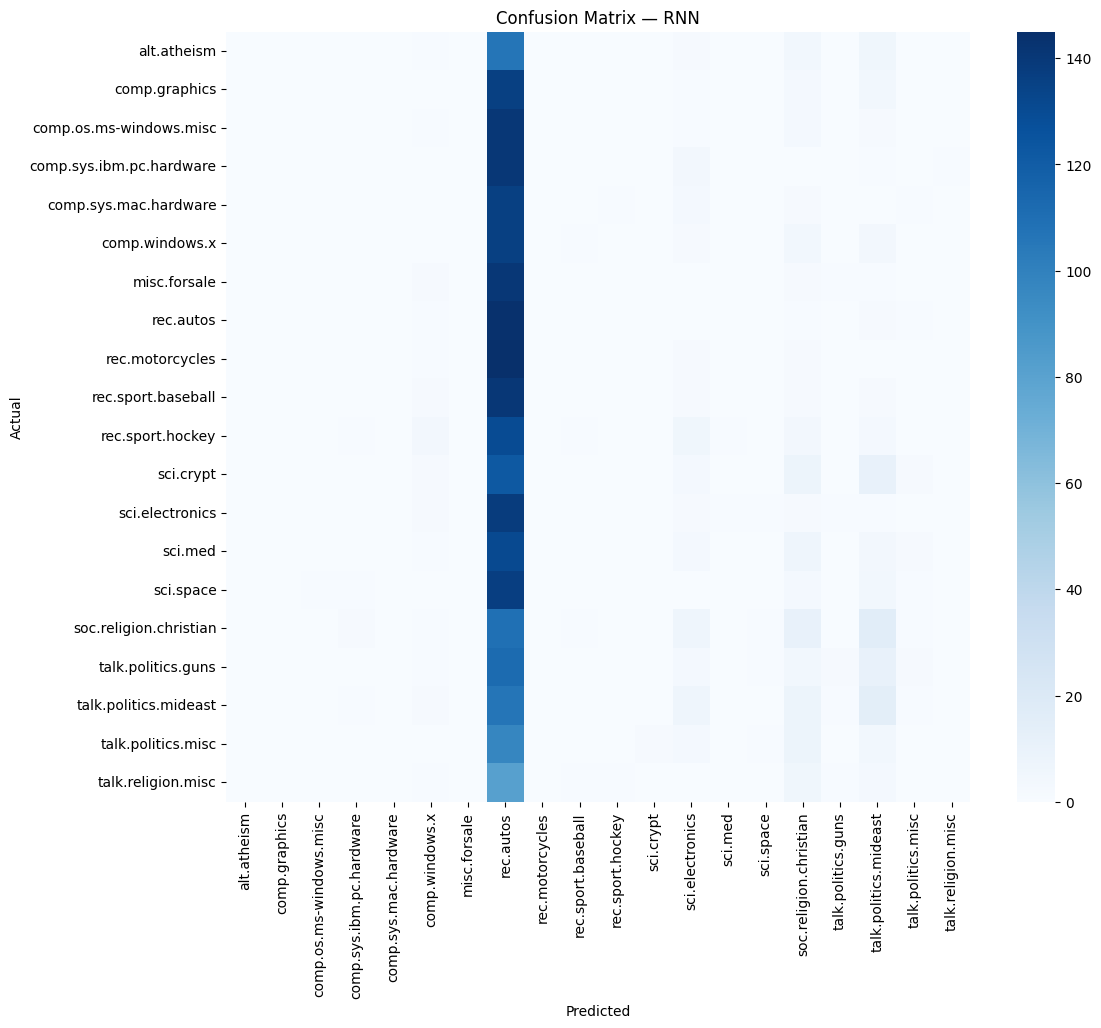



Training: GRU
Epoch 1/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 8s 31ms/step - accuracy: 0.0531 - loss: 2.9917 - val_accuracy: 0.0605 - val_loss: 2.9861
Epoch 2/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.0598 - loss: 2.9739 - val_accuracy: 0.0609 - val_loss: 2.9639
Epoch 3/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.0622 - loss: 2.9518 - val_accuracy: 0.0634 - val_loss: 2.9666
Epoch 4/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.0678 - loss: 2.9324 - val_accuracy: 0.0665 - val_loss: 2.9547
Epoch 5/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.0864 - loss: 2.8934 - val_accuracy: 0.0662 - val_loss: 2.9738
Epoch 6/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - accuracy: 0.1017 - loss: 2.8499 - val_accuracy: 0.0683 - val_loss: 3.0117
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step

GRU
Accuracy : 0.06654867256637167
Precision: 0.05994654373108332
Recall   : 0.06654867256637167
F1 Score : 0.030227748614039658


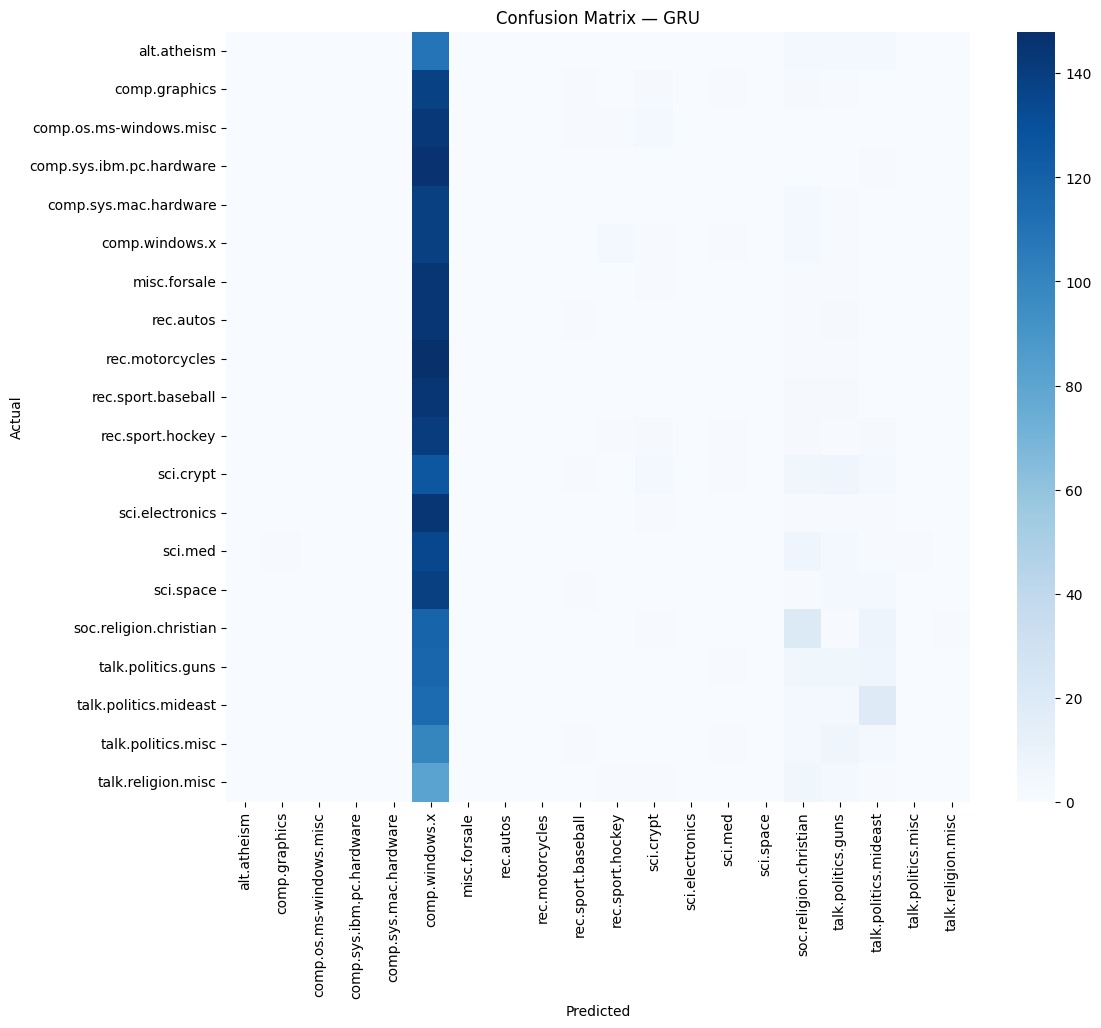



Training: LSTM
Epoch 1/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step - accuracy: 0.0573 - loss: 2.9921 - val_accuracy: 0.0609 - val_loss: 2.9854
Epoch 2/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - accuracy: 0.0586 - loss: 3.0337 - val_accuracy: 0.0538 - val_loss: 3.0228
Epoch 3/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - accuracy: 0.0505 - loss: 2.9985 - val_accuracy: 0.0563 - val_loss: 2.9875
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step

LSTM
Accuracy : 0.05946902654867257
Precision: 0.008922109141530986
Recall   : 0.05946902654867257
F1 Score : 0.012614719663125695


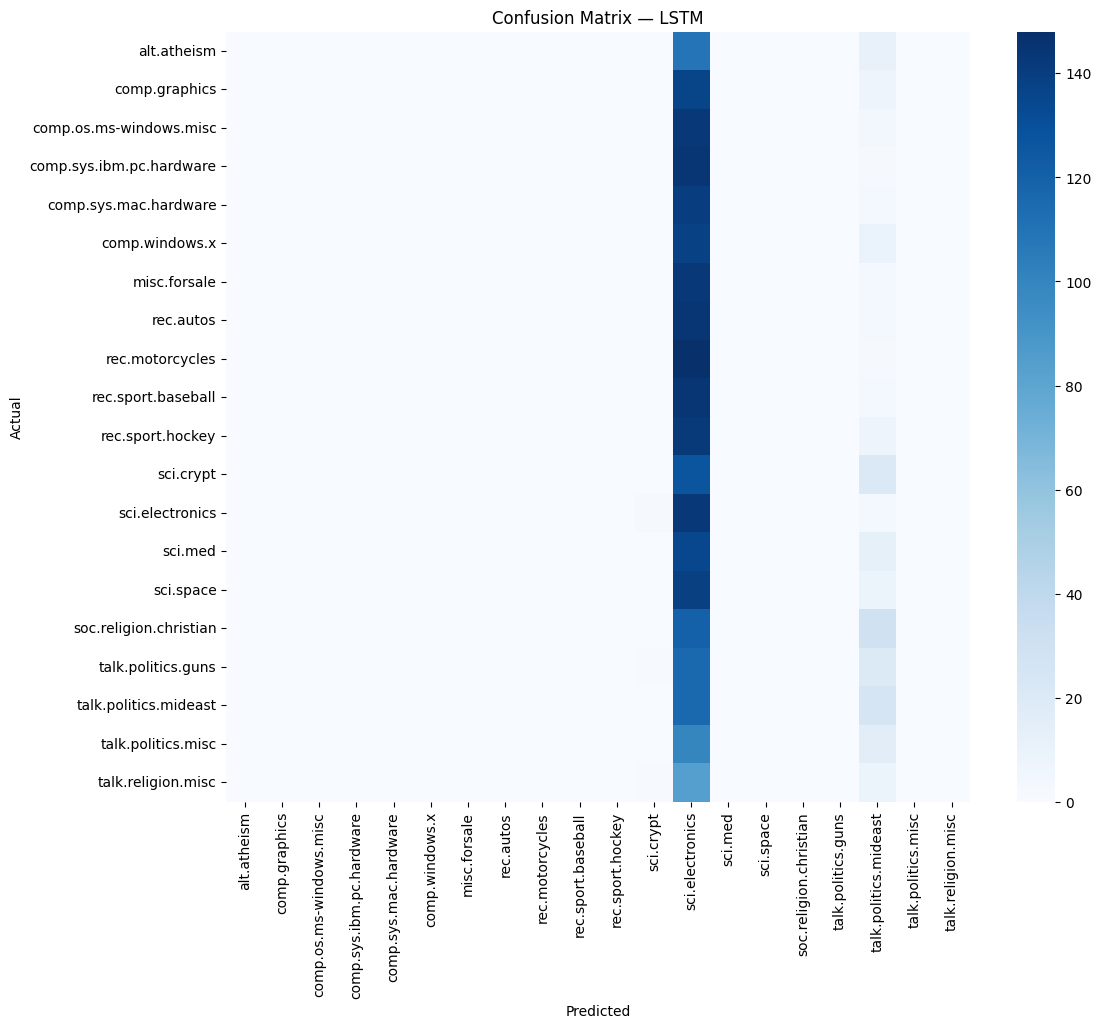



Training: BiLSTM
Epoch 1/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 8s 52ms/step - accuracy: 0.0985 - loss: 2.7381 - val_accuracy: 0.1968 - val_loss: 2.3790
Epoch 2/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - accuracy: 0.2951 - loss: 1.9823 - val_accuracy: 0.4687 - val_loss: 1.5475
Epoch 3/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step - accuracy: 0.6144 - loss: 1.0922 - val_accuracy: 0.6680 - val_loss: 1.0246
Epoch 4/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step - accuracy: 0.7863 - loss: 0.6262 - val_accuracy: 0.7062 - val_loss: 0.9445
Epoch 5/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 9s 92ms/step - accuracy: 0.8883 - loss: 0.3733 - val_accuracy: 0.7412 - val_loss: 0.9730
Epoch 6/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 6s 50ms/step - accuracy: 0.9298 - loss: 0.2420 - val_accuracy: 0.7742 - val_loss: 0.9148
Epoch 7/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 5s 47ms/step - accuracy: 0.9468 - loss: 0.1985 - val_accuracy: 0.7802 - val_loss: 0.9754
Epoch 8/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 5s 47ms/step - accuracy: 0.9685 - loss

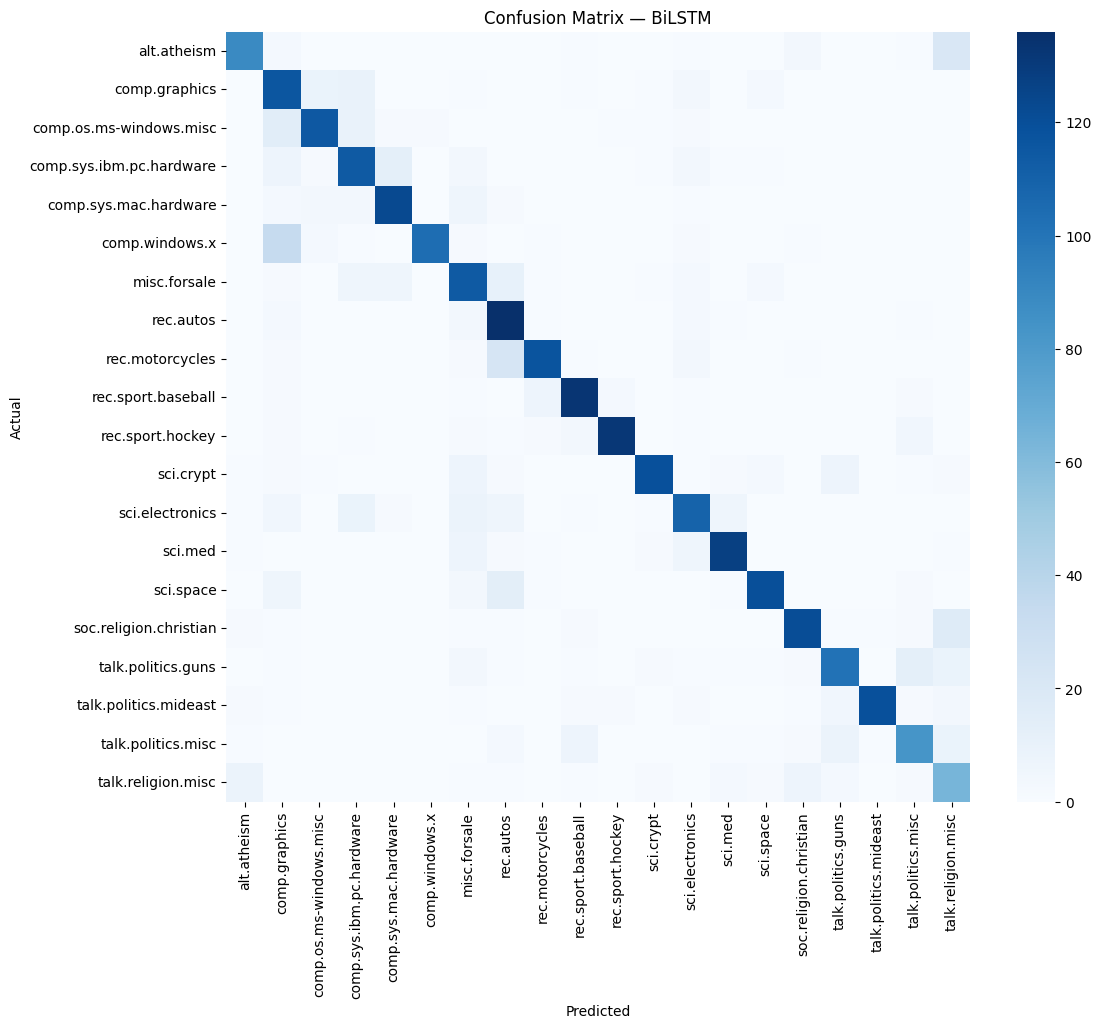



Training: BiGRU
Epoch 1/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 8s 46ms/step - accuracy: 0.0994 - loss: 2.8182 - val_accuracy: 0.2414 - val_loss: 2.2296
Epoch 2/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - accuracy: 0.3318 - loss: 1.8359 - val_accuracy: 0.4262 - val_loss: 1.5667
Epoch 3/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step - accuracy: 0.5024 - loss: 1.3116 - val_accuracy: 0.5434 - val_loss: 1.3406
Epoch 4/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - accuracy: 0.6566 - loss: 0.9459 - val_accuracy: 0.6549 - val_loss: 1.1315
Epoch 5/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step - accuracy: 0.7976 - loss: 0.5723 - val_accuracy: 0.7207 - val_loss: 1.0001
Epoch 6/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step - accuracy: 0.8690 - loss: 0.3842 - val_accuracy: 0.7158 - val_loss: 1.1186
Epoch 7/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - accuracy: 0.9049 - loss: 0.2852 - val_accuracy: 0.7554 - val_loss: 1.0324
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step

BiGRU
Accuracy : 0.7295575221238938
Pr

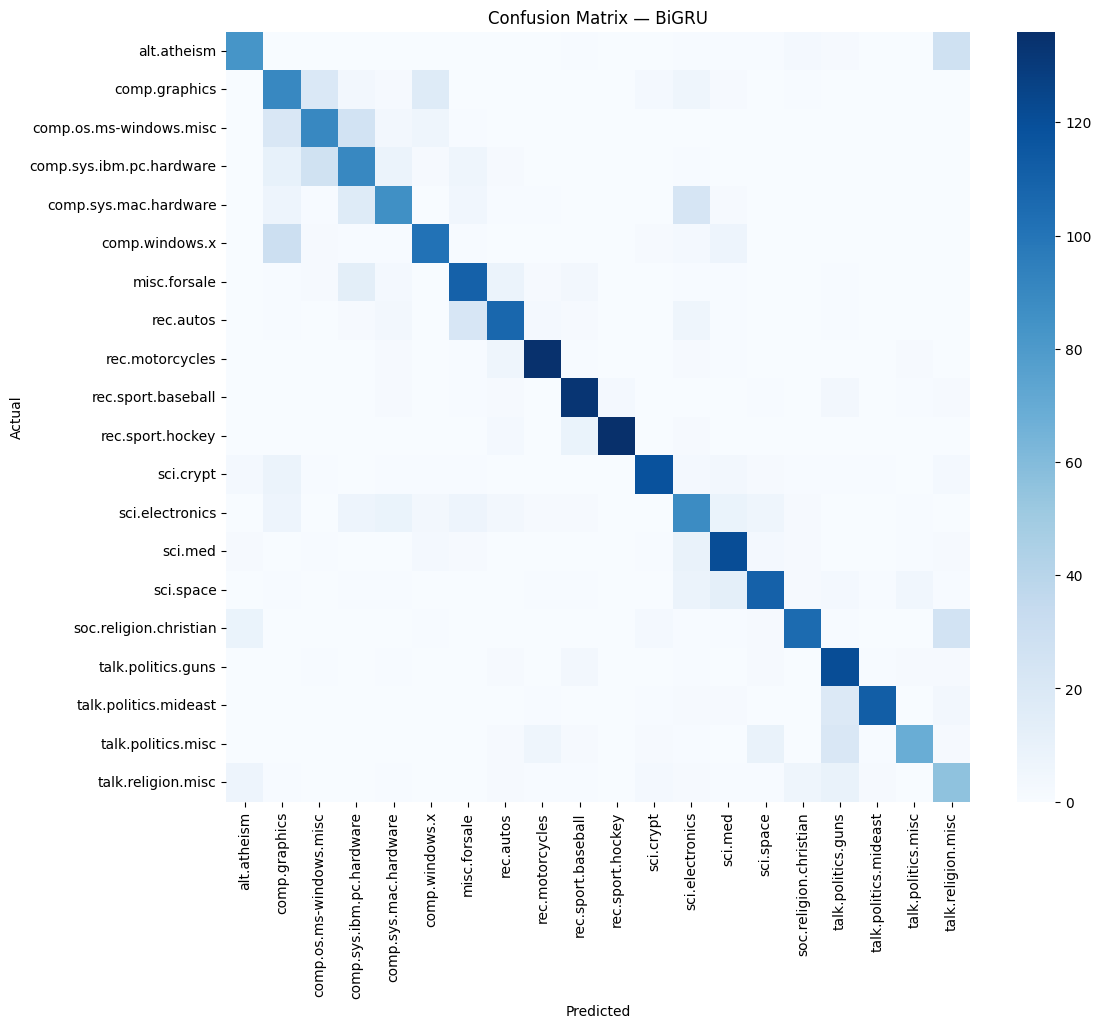

In [22]:
RNN_MODELS = [
    "RNN",
    "GRU",
    "LSTM",
    "BiLSTM",
    "BiGRU"
]

trained_rnn_models = {}

for architecture in RNN_MODELS:

    print("\n\n============================")
    print("Training:", architecture)
    print("============================")

    model = build_rnn_model(
        architecture=architecture,
        units=128
    )

    model.fit(
        X_train_pad,
        y_train,

        validation_data=(
            X_val_pad,
            y_val
        ),

        epochs=10,
        batch_size=128,

        callbacks=[
            EarlyStopping(
                patience=2,
                restore_best_weights=True
            )
        ],

        verbose=1
    )

    trained_rnn_models[architecture] = model

    probs = model.predict(
        X_test_pad,
        batch_size=128
    )

    pred = np.argmax(
        probs,
        axis=1
    )

    evaluate_model(
        architecture,
        y_test,
        pred
    )


In [23]:
def create_ngrams(
    text,
    n
):

    tokens = text.split()

    if len(tokens) < n:
        return []

    return [
        "_".join(tokens[i:i+n])
        for i in range(
            len(tokens) - n + 1
        )
    ]


In [24]:
def make_ngram_texts(
    texts,
    n
):

    output = []

    for text in texts:

        grams = create_ngrams(
            text,
            n
        )

        output.append(
            " ".join(grams)
        )

    return output



N-GRAM: 5
Epoch 1/5
103/103 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.1691 - loss: 2.8741 - val_accuracy: 0.2956 - val_loss: 2.6199
Epoch 2/5
103/103 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3426 - loss: 2.3162 - val_accuracy: 0.3154 - val_loss: 2.2885
Epoch 3/5
103/103 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3697 - loss: 2.1011 - val_accuracy: 0.3161 - val_loss: 2.2369
Epoch 4/5
103/103 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3774 - loss: 2.0377 - val_accuracy: 0.3179 - val_loss: 2.2208
Epoch 5/5
103/103 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3789 - loss: 2.0001 - val_accuracy: 0.3158 - val_loss: 2.2137
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step

ANN N-gram=5
Accuracy : 0.31610619469026546
Precision: 0.7068933522120304
Recall   : 0.31610619469026546
F1 Score : 0.3767232746181946


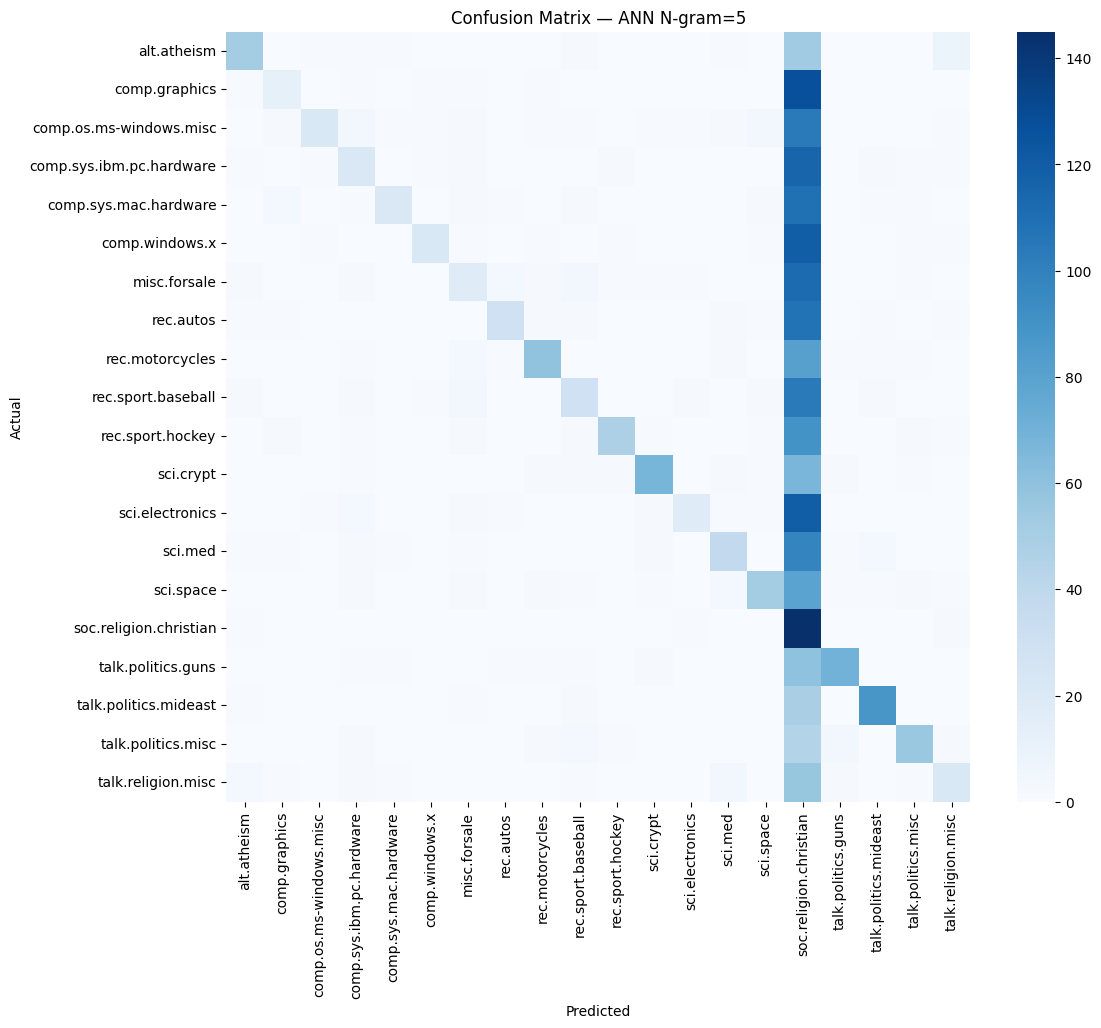


N-GRAM: 10
Epoch 1/5
103/103 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.1213 - loss: 2.9186 - val_accuracy: 0.1968 - val_loss: 2.7662
Epoch 2/5
103/103 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.2798 - loss: 2.5025 - val_accuracy: 0.2481 - val_loss: 2.4821
Epoch 3/5
103/103 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3094 - loss: 2.2857 - val_accuracy: 0.2471 - val_loss: 2.4268
Epoch 4/5
103/103 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3127 - loss: 2.2312 - val_accuracy: 0.2464 - val_loss: 2.4147
Epoch 5/5
103/103 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3140 - loss: 2.2002 - val_accuracy: 0.2464 - val_loss: 2.4090
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step

ANN N-gram=10
Accuracy : 0.24176991150442478
Precision: 0.8108404940433739
Recall   : 0.24176991150442478
F1 Score : 0.30255968415158563


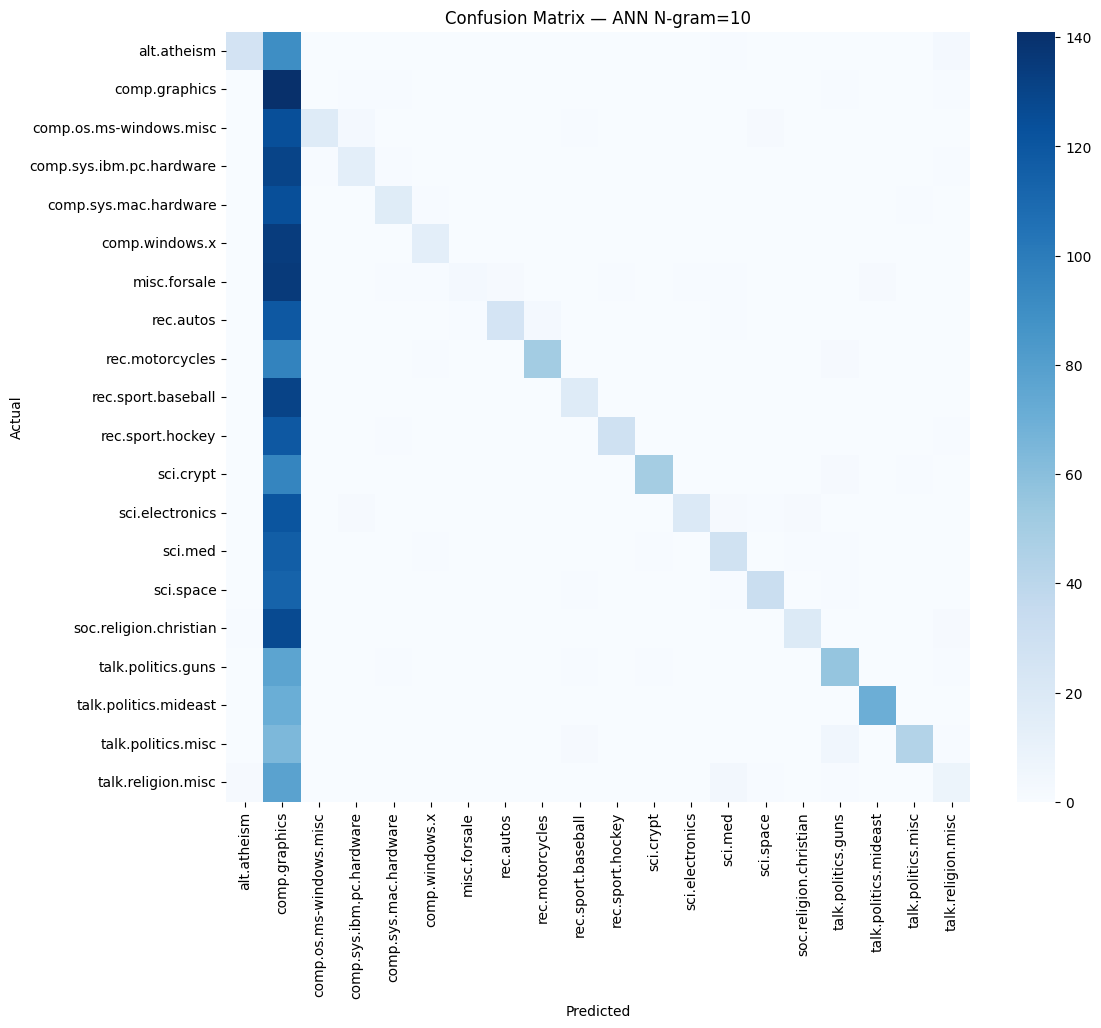


N-GRAM: 100
Epoch 1/5
103/103 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.0546 - loss: 2.9920 - val_accuracy: 0.0499 - val_loss: 2.9888
Epoch 2/5
103/103 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.0547 - loss: 2.9819 - val_accuracy: 0.0552 - val_loss: 2.9836
Epoch 3/5
103/103 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.0570 - loss: 2.9722 - val_accuracy: 0.0566 - val_loss: 2.9794
Epoch 4/5
103/103 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.0647 - loss: 2.9607 - val_accuracy: 0.0566 - val_loss: 2.9778
Epoch 5/5
103/103 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.0677 - loss: 2.9505 - val_accuracy: 0.0570 - val_loss: 2.9769
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step

ANN N-gram=100
Accuracy : 0.05380530973451327
Precision: 0.20618181018531606
Recall   : 0.05380530973451327
F1 Score : 0.00988833638865779


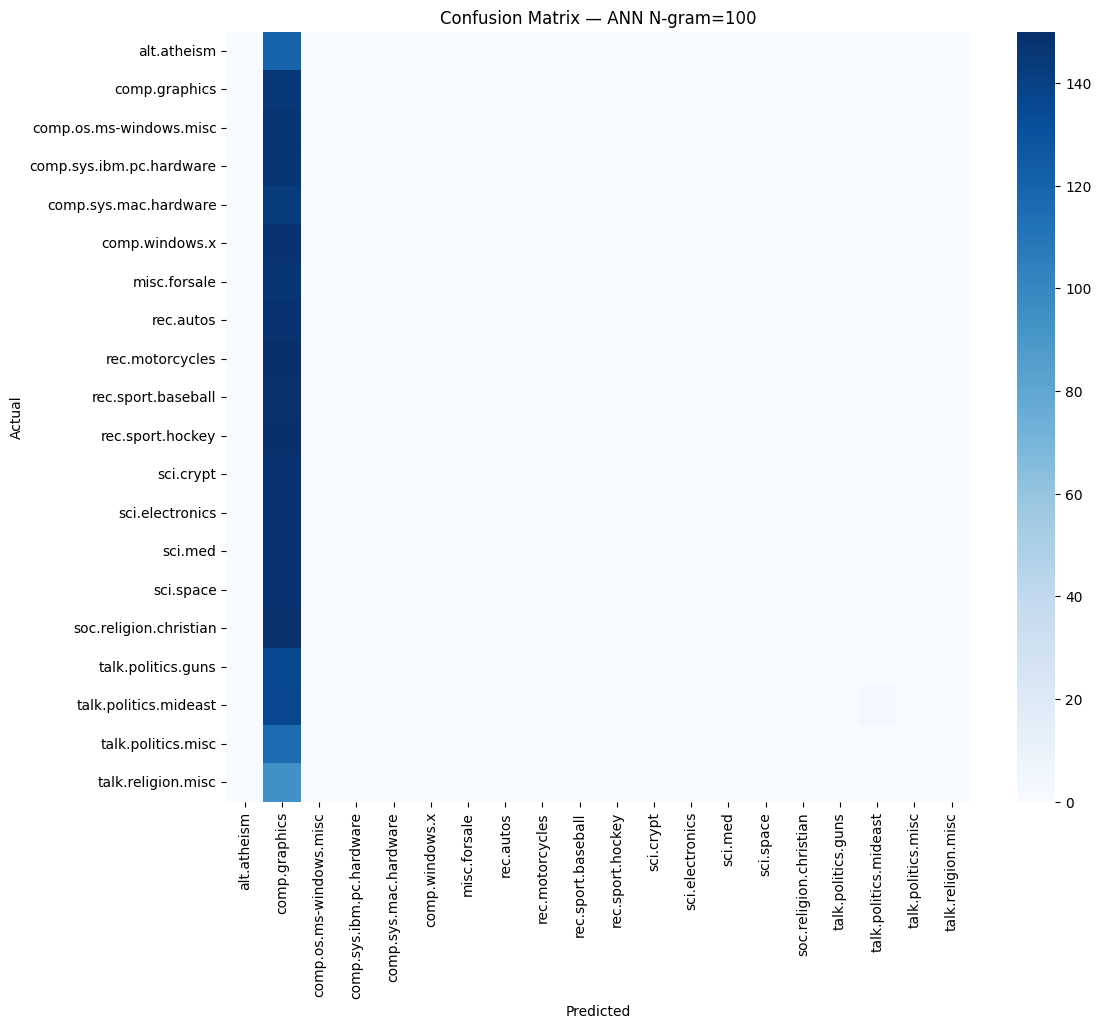

In [25]:
NGRAM_RESULTS = []

for n in [5, 10, 100]:

    print("\n==============================")
    print("N-GRAM:", n)
    print("==============================")

    train_ngram = make_ngram_texts(
        X_train_clean,
        n
    )

    val_ngram = make_ngram_texts(
        X_val_clean,
        n
    )

    test_ngram = make_ngram_texts(
        X_test_clean,
        n
    )

    ngram_vectorizer = TfidfVectorizer(
        max_features=10000,
        ngram_range=(1, 1),
        min_df=2
    )

    X_ng_train = ngram_vectorizer.fit_transform(
        train_ngram
    )

    X_ng_val = ngram_vectorizer.transform(
        val_ngram
    )

    X_ng_test = ngram_vectorizer.transform(
        test_ngram
    )

    ngram_ann = Sequential([

        Dense(
            256,
            activation="relu",
            input_shape=(
                X_ng_train.shape[1],
            )
        ),

        Dropout(0.4),

        Dense(
            128,
            activation="relu"
        ),

        Dropout(0.3),

        Dense(
            NUM_CLASSES,
            activation="softmax"
        )
    ])

    ngram_ann.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    ngram_ann.fit(
        X_ng_train.toarray(),
        y_train,

        validation_data=(
            X_ng_val.toarray(),
            y_val
        ),

        epochs=5,
        batch_size=128,
        verbose=1
    )

    probs = ngram_ann.predict(
        X_ng_test.toarray(),
        batch_size=128
    )

    pred = np.argmax(
        probs,
        axis=1
    )

    evaluate_model(
        f"ANN N-gram={n}",
        y_test,
        pred
    )


In [26]:
train_tokens = [
    text.split()
    for text in X_train_clean
]

val_tokens = [
    text.split()
    for text in X_val_clean
]

test_tokens = [
    text.split()
    for text in X_test_clean
]

In [27]:
word2vec_model = Word2Vec(
    sentences=train_tokens,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    sg=1,
    seed=SEED
)

print(print("NumPy version:", np.__version__)
print("Setup is ready for segmentation!")
    "Word2Vec vocabulary:",
    len(word2vec_model.wv)
)

Word2Vec vocabulary: 47773


In [28]:
embedding_matrix_w2v = np.zeros(
    (VOCAB_SIZE, 100)
)

for word, index in tokenizer.word_index.items():

    if index >= VOCAB_SIZE:
        continue

    if word in word2vec_model.wv:

        embedding_matrix_w2v[index] = (
            word2vec_model.wv[word]
        )


In [29]:
def build_pretrained_embedding_model(
    embedding_matrix,
    embedding_dim,
    architecture="LSTM",
    trainable=False
):

    model = Sequential([

        Embedding(
            input_dim=embedding_matrix.shape[0],
            output_dim=embedding_dim,
            weights=[embedding_matrix],
            input_length=MAX_LEN,
            trainable=trainable
        )
    ])

    if architecture == "RNN":

        model.add(
            SimpleRNN(128)
        )

    elif architecture == "GRU":

        model.add(
            GRU(128)
        )

    elif architecture == "LSTM":

        model.add(
            LSTM(128)
        )

    elif architecture == "BiLSTM":

        model.add(
            Bidirectional(
                LSTM(128)
            )
        )

    elif architecture == "BiGRU":

        model.add(
            Bidirectional(
                GRU(128)
            )
        )

    model.add(
        Dropout(0.4)
    )

    model.add(
        Dense(
            128,
            activation="relu"
        )
    )

    model.add(
        Dropout(0.3)
    )

    model.add(
        Dense(
            NUM_CLASSES,
            activation="softmax"
        )
    )

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model



Training Word2Vec + RNN
Epoch 1/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 8s 36ms/step - accuracy: 0.0561 - loss: 2.9989 - val_accuracy: 0.0588 - val_loss: 2.9696
Epoch 2/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.0662 - loss: 2.9586 - val_accuracy: 0.0665 - val_loss: 2.9493
Epoch 3/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - accuracy: 0.0714 - loss: 2.9389 - val_accuracy: 0.0669 - val_loss: 2.9361
Epoch 4/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - accuracy: 0.0757 - loss: 2.9282 - val_accuracy: 0.0758 - val_loss: 2.9386
Epoch 5/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.0783 - loss: 2.9182 - val_accuracy: 0.0779 - val_loss: 2.9241
Epoch 6/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.0810 - loss: 2.9109 - val_accuracy: 0.0811 - val_loss: 2.9243
Epoch 7/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.0825 - loss: 2.9038 - val_accuracy: 0.0726 - val_loss: 2.9294
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step

Word2Vec + RNN
Accuracy : 0.0828318584

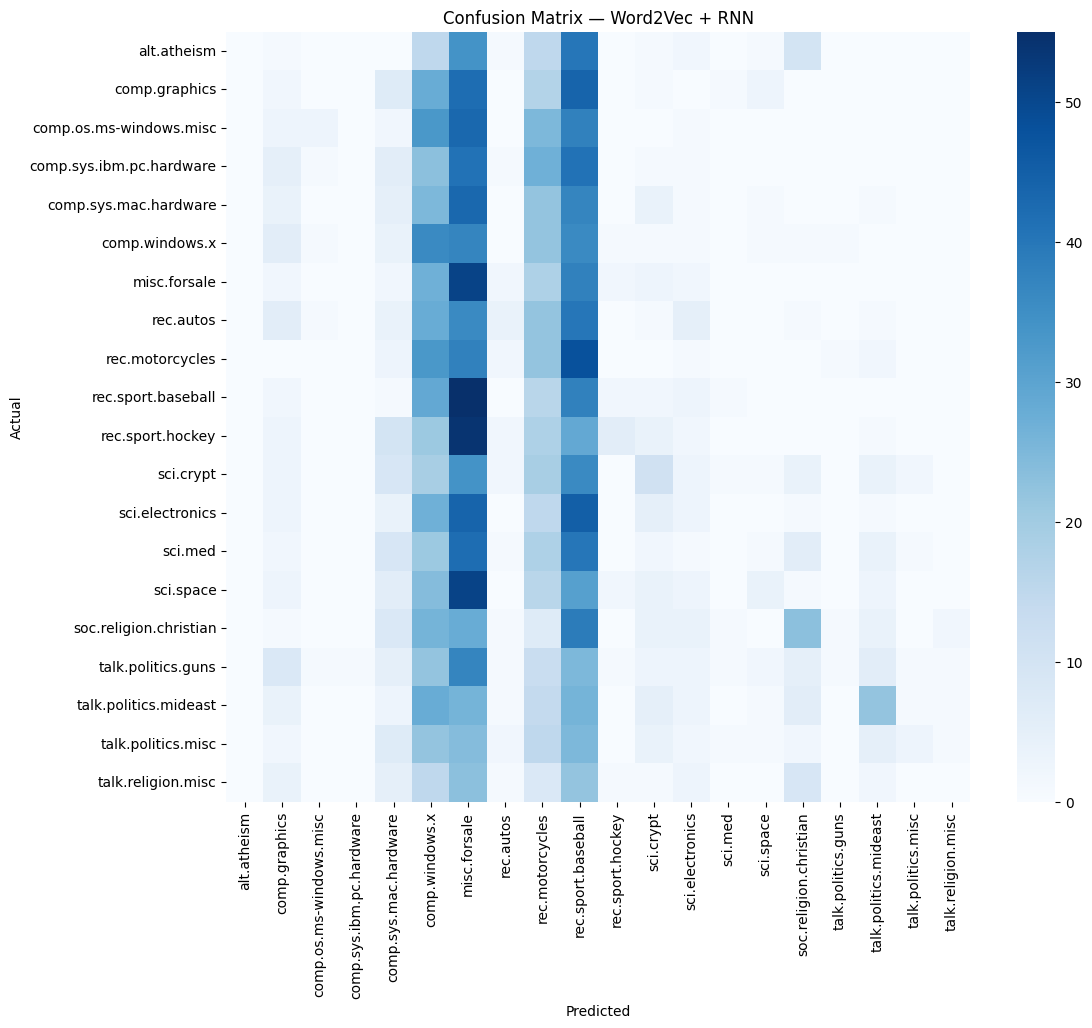


Training Word2Vec + GRU
Epoch 1/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.0582 - loss: 2.9731 - val_accuracy: 0.0736 - val_loss: 2.9330
Epoch 2/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.0631 - loss: 3.0944 - val_accuracy: 0.0577 - val_loss: 2.9926
Epoch 3/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - accuracy: 0.0510 - loss: 2.9938 - val_accuracy: 0.0524 - val_loss: 2.9920
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step

Word2Vec + GRU
Accuracy : 0.07150442477876107
Precision: 0.15733715374943827
Recall   : 0.07150442477876107
F1 Score : 0.037784406756620995


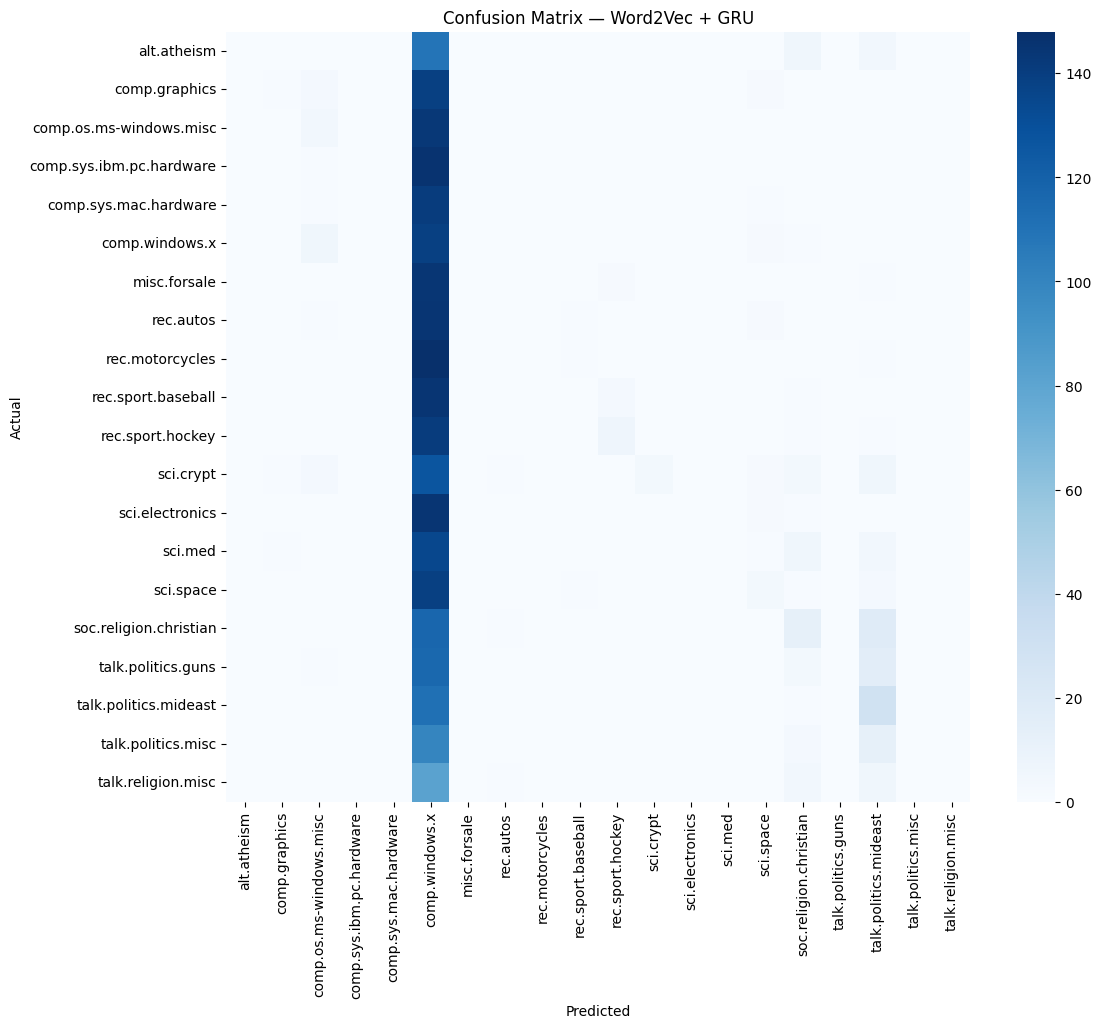


Training Word2Vec + LSTM
Epoch 1/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.0599 - loss: 2.9765 - val_accuracy: 0.0630 - val_loss: 2.9740
Epoch 2/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.0685 - loss: 2.9559 - val_accuracy: 0.0630 - val_loss: 2.9640
Epoch 3/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.0699 - loss: 2.9356 - val_accuracy: 0.1193 - val_loss: 2.7650
Epoch 4/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - accuracy: 0.0736 - loss: 2.9155 - val_accuracy: 0.0991 - val_loss: 2.7808
Epoch 5/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.0880 - loss: 2.8679 - val_accuracy: 0.1012 - val_loss: 2.8196
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step

Word2Vec + LSTM
Accuracy : 0.12106194690265487
Precision: 0.152614982061848
Recall   : 0.12106194690265487
F1 Score : 0.06057017924045631


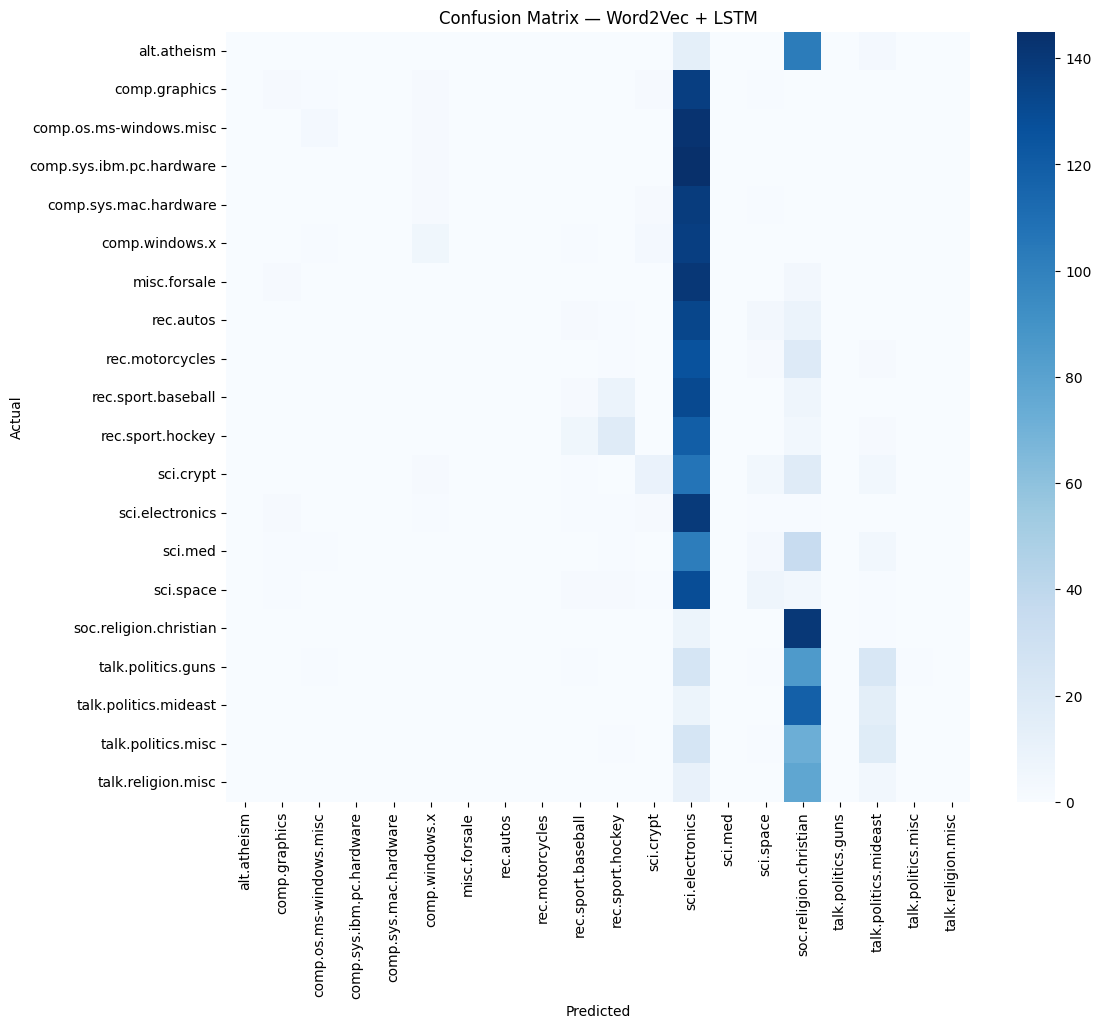


Training Word2Vec + BiLSTM
Epoch 1/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - accuracy: 0.2406 - loss: 2.3175 - val_accuracy: 0.4372 - val_loss: 1.5859
Epoch 2/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step - accuracy: 0.4557 - loss: 1.5606 - val_accuracy: 0.5515 - val_loss: 1.2905
Epoch 3/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - accuracy: 0.5306 - loss: 1.3693 - val_accuracy: 0.5869 - val_loss: 1.1799
Epoch 4/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.6022 - loss: 1.1596 - val_accuracy: 0.6329 - val_loss: 1.0713
Epoch 5/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step - accuracy: 0.6248 - loss: 1.1416 - val_accuracy: 0.6556 - val_loss: 1.0370
Epoch 6/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - accuracy: 0.6560 - loss: 1.0206 - val_accuracy: 0.6570 - val_loss: 1.0401
Epoch 7/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step - accuracy: 0.6782 - loss: 0.9658 - val_accuracy: 0.6800 - val_loss: 0.9700
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step

Word2Vec + BiLSTM
Accuracy : 0.6906

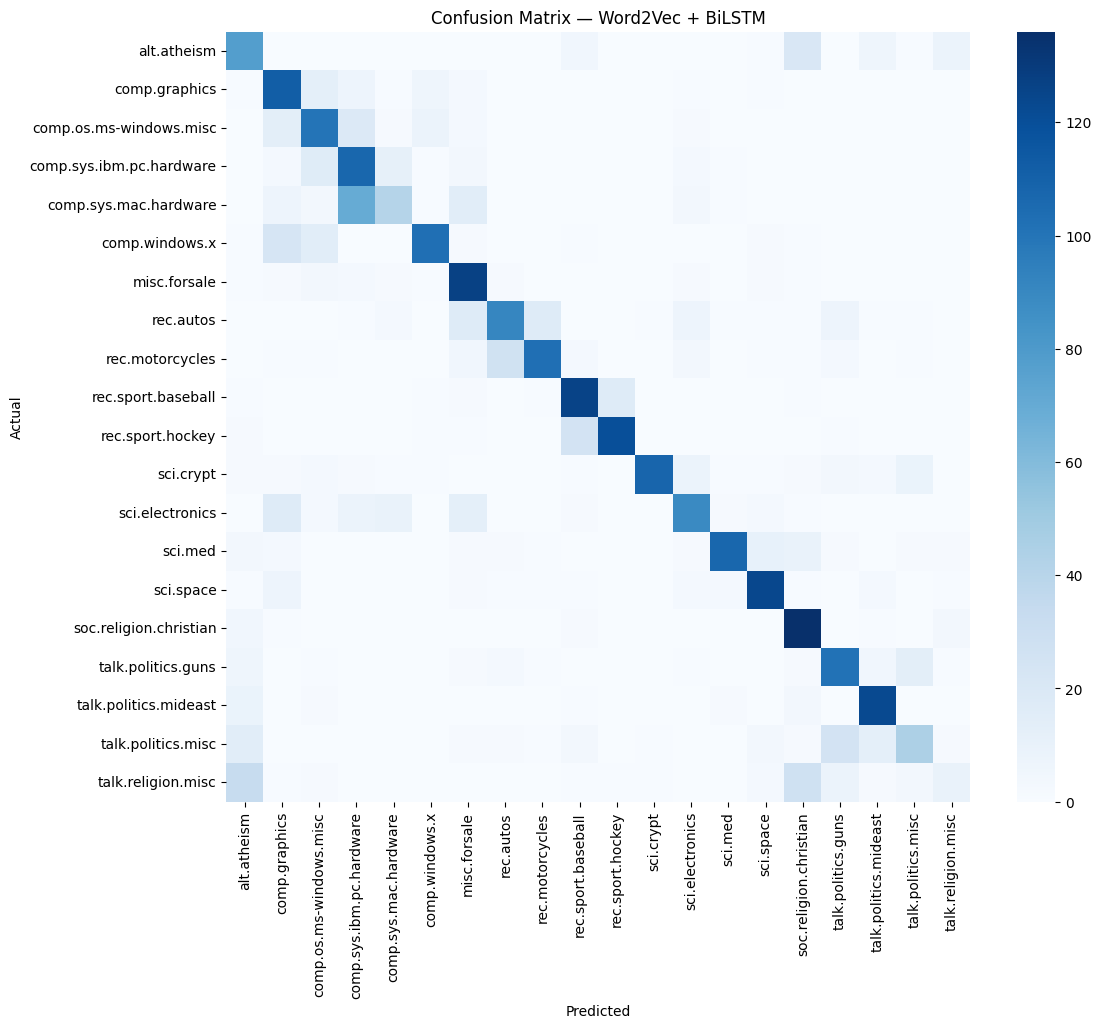


Training Word2Vec + BiGRU
Epoch 1/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 7s 50ms/step - accuracy: 0.1537 - loss: 2.6043 - val_accuracy: 0.3381 - val_loss: 1.9808
Epoch 2/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step - accuracy: 0.3507 - loss: 1.8101 - val_accuracy: 0.4549 - val_loss: 1.4666
Epoch 3/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - accuracy: 0.4914 - loss: 1.3724 - val_accuracy: 0.5873 - val_loss: 1.1392
Epoch 4/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - accuracy: 0.5820 - loss: 1.1565 - val_accuracy: 0.6248 - val_loss: 1.0402
Epoch 5/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.6287 - loss: 1.0536 - val_accuracy: 0.6414 - val_loss: 1.0136
Epoch 6/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - accuracy: 0.6583 - loss: 0.9757 - val_accuracy: 0.6768 - val_loss: 0.9339
Epoch 7/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - accuracy: 0.6916 - loss: 0.9084 - val_accuracy: 0.6850 - val_loss: 0.9139
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step

Word2Vec + BiGRU
Accuracy : 0.702654

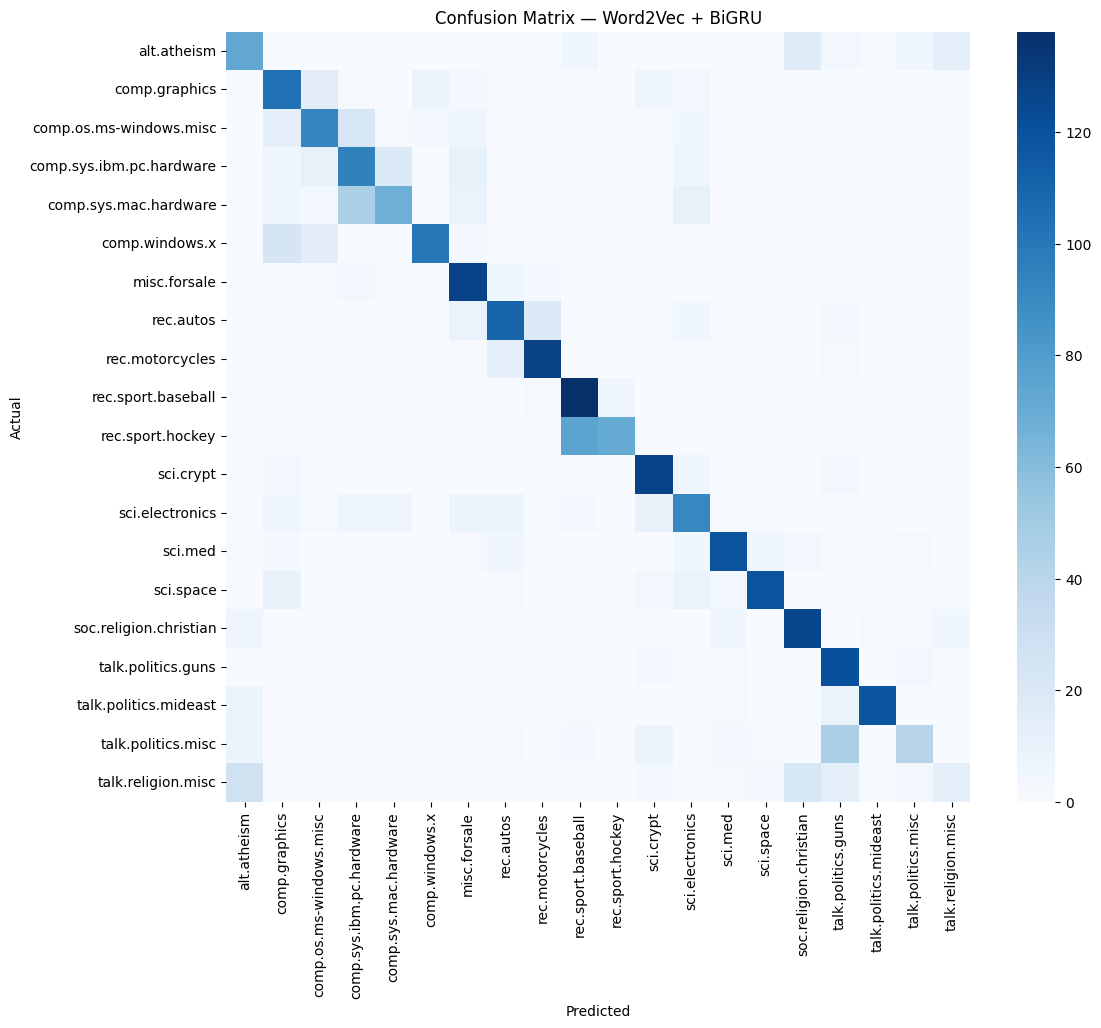

In [30]:
for architecture in RNN_MODELS:

    print(
        "\nTraining Word2Vec +",
        architecture
    )

    model = build_pretrained_embedding_model(
        embedding_matrix_w2v,
        100,
        architecture=architecture,
        trainable=False
    )

    model.fit(
        X_train_pad,
        y_train,

        validation_data=(
            X_val_pad,
            y_val
        ),

        epochs=7,
        batch_size=128,

        callbacks=[
            EarlyStopping(
                patience=2,
                restore_best_weights=True
            )
        ],

        verbose=1
    )

    probs = model.predict(
        X_test_pad,
        batch_size=128
    )

    pred = np.argmax(
        probs,
        axis=1
    )

    evaluate_model(
        f"Word2Vec + {architecture}",
        y_test,
        pred
    )

In [31]:
fasttext_model = FastText(
    sentences=train_tokens,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    seed=SEED
)

print(
    "FastText vocabulary:",
    len(fasttext_model.wv)
)

FastText vocabulary: 47773


In [32]:
embedding_matrix_fasttext = np.zeros(
    (VOCAB_SIZE, 100)
)

for word, index in tokenizer.word_index.items():

    if index >= VOCAB_SIZE:
        continue

    embedding_matrix_fasttext[index] = (
        fasttext_model.wv[word]
    )


Training FastText + RNN
Epoch 1/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 8s 36ms/step - accuracy: 0.0539 - loss: 3.0363 - val_accuracy: 0.0605 - val_loss: 2.9763
Epoch 2/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.0647 - loss: 2.9712 - val_accuracy: 0.0644 - val_loss: 2.9627
Epoch 3/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.0617 - loss: 2.9584 - val_accuracy: 0.0658 - val_loss: 2.9545
Epoch 4/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - accuracy: 0.0673 - loss: 2.9495 - val_accuracy: 0.0662 - val_loss: 2.9514
Epoch 5/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.0707 - loss: 2.9424 - val_accuracy: 0.0673 - val_loss: 2.9504
Epoch 6/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.0712 - loss: 2.9388 - val_accuracy: 0.0676 - val_loss: 2.9479
Epoch 7/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.0736 - loss: 2.9298 - val_accuracy: 0.0722 - val_loss: 2.9464
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step

FastText + RNN
Accuracy : 0.0704424778

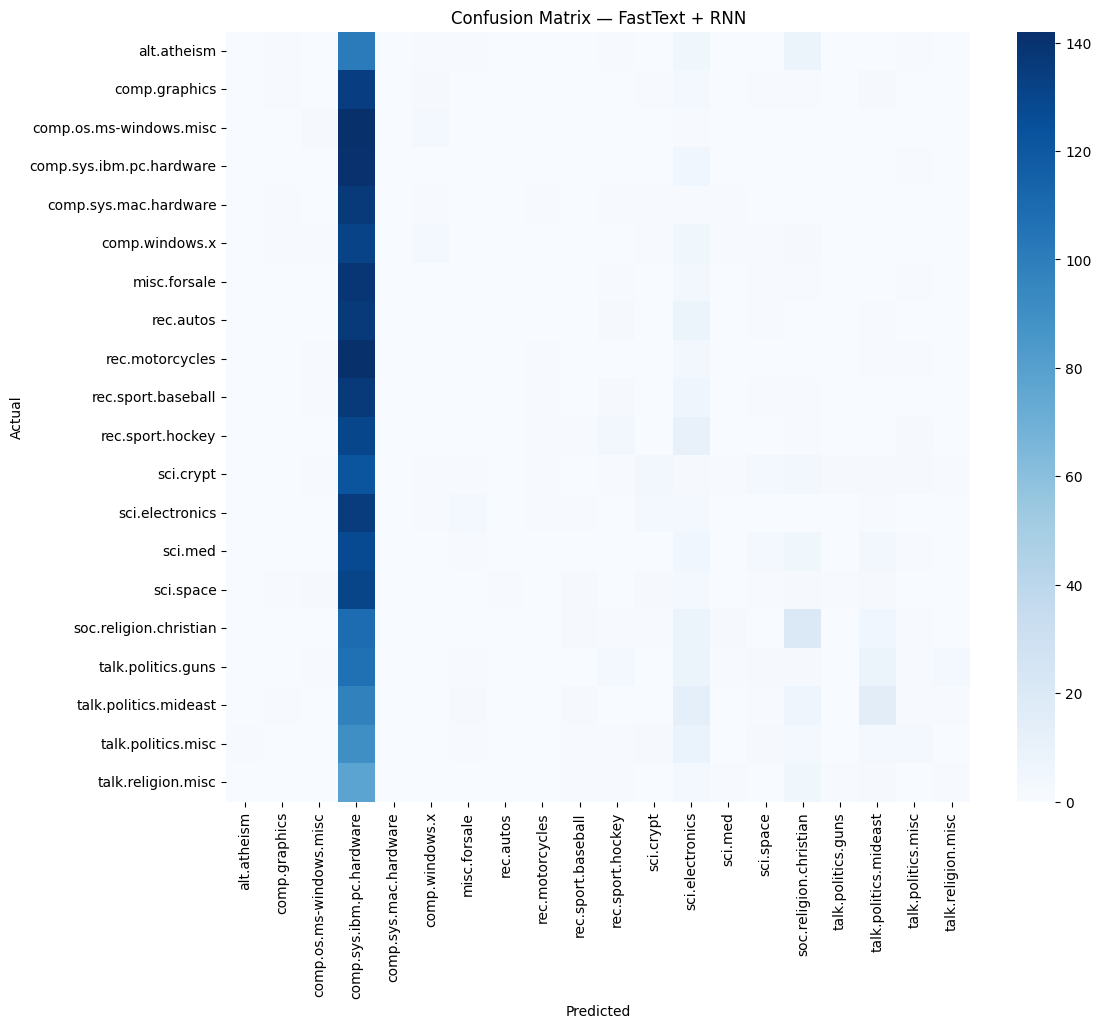


Training FastText + GRU
Epoch 1/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - accuracy: 0.0600 - loss: 2.9691 - val_accuracy: 0.0704 - val_loss: 2.9359
Epoch 2/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.0763 - loss: 2.9307 - val_accuracy: 0.0761 - val_loss: 2.9075
Epoch 3/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.0842 - loss: 2.9047 - val_accuracy: 0.0988 - val_loss: 2.8544
Epoch 4/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.1509 - loss: 2.6486 - val_accuracy: 0.1883 - val_loss: 2.4942
Epoch 5/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.1951 - loss: 2.4489 - val_accuracy: 0.2227 - val_loss: 2.3438
Epoch 6/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - accuracy: 0.2237 - loss: 2.3547 - val_accuracy: 0.2319 - val_loss: 2.4953
Epoch 7/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.2539 - loss: 2.2386 - val_accuracy: 0.3448 - val_loss: 1.8753
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step

FastText + GRU
Accuracy : 0.3539823008

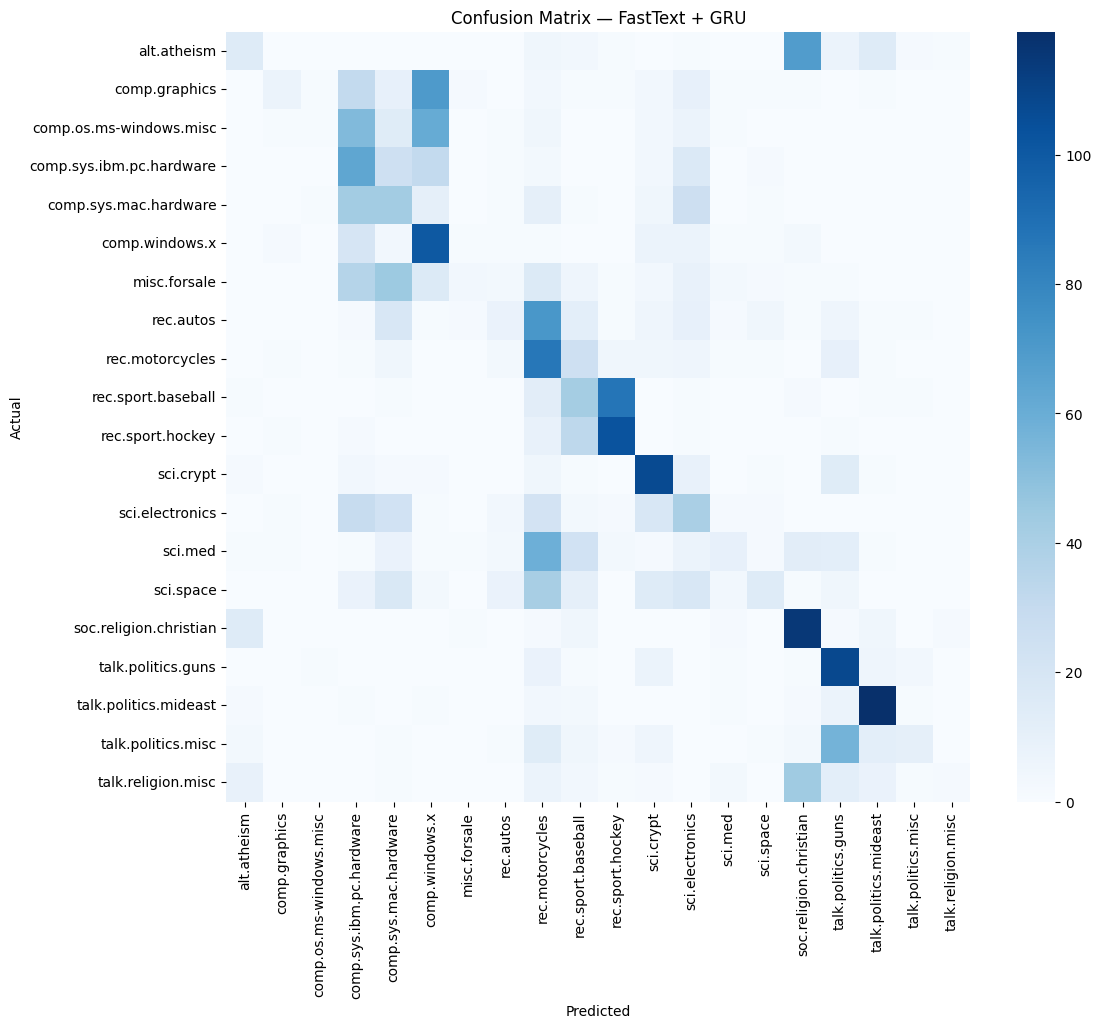


Training FastText + LSTM
Epoch 1/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.0650 - loss: 2.9613 - val_accuracy: 0.0786 - val_loss: 2.9224
Epoch 2/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.0930 - loss: 2.8341 - val_accuracy: 0.1065 - val_loss: 2.7707
Epoch 3/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - accuracy: 0.1195 - loss: 2.7012 - val_accuracy: 0.1016 - val_loss: 2.9247
Epoch 4/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.1025 - loss: 2.7398 - val_accuracy: 0.1147 - val_loss: 2.6583
Epoch 5/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.0972 - loss: 2.8522 - val_accuracy: 0.0804 - val_loss: 2.8950
Epoch 6/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.0853 - loss: 2.8962 - val_accuracy: 0.0839 - val_loss: 2.9044
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step

FastText + LSTM
Accuracy : 0.11823008849557522
Precision: 0.22342012270295017
Recall   : 0.11823008849557522
F1 Score : 0.06069975459180914


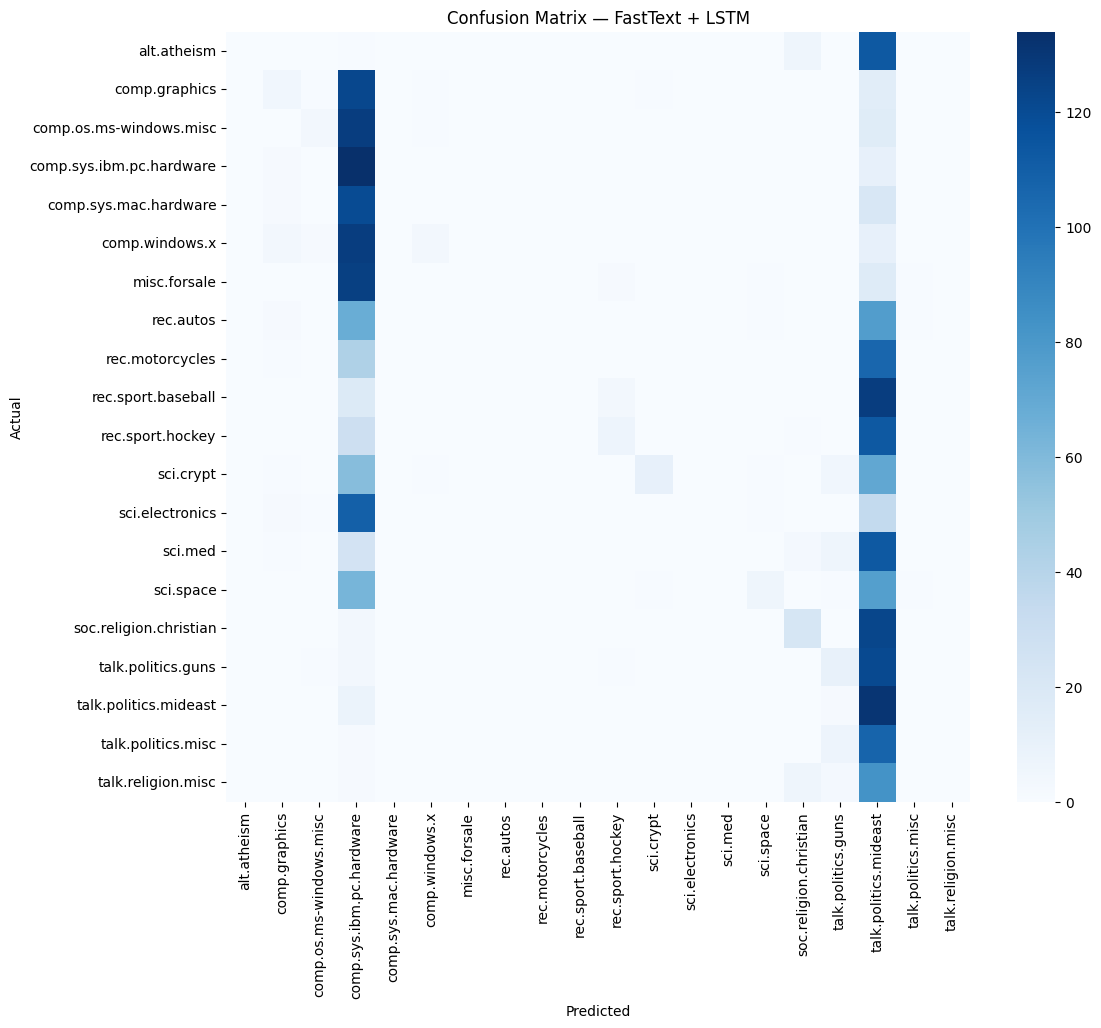


Training FastText + BiLSTM
Epoch 1/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - accuracy: 0.2266 - loss: 2.3748 - val_accuracy: 0.4219 - val_loss: 1.7010
Epoch 2/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - accuracy: 0.4169 - loss: 1.6896 - val_accuracy: 0.4970 - val_loss: 1.4826
Epoch 3/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step - accuracy: 0.4861 - loss: 1.5023 - val_accuracy: 0.5310 - val_loss: 1.3893
Epoch 4/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - accuracy: 0.5420 - loss: 1.3499 - val_accuracy: 0.5706 - val_loss: 1.3145
Epoch 5/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - accuracy: 0.5738 - loss: 1.2473 - val_accuracy: 0.5862 - val_loss: 1.2489
Epoch 6/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step - accuracy: 0.6113 - loss: 1.1678 - val_accuracy: 0.6021 - val_loss: 1.2074
Epoch 7/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - accuracy: 0.6358 - loss: 1.0922 - val_accuracy: 0.6237 - val_loss: 1.1555
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step

FastText + BiLSTM
Accuracy : 0.6392

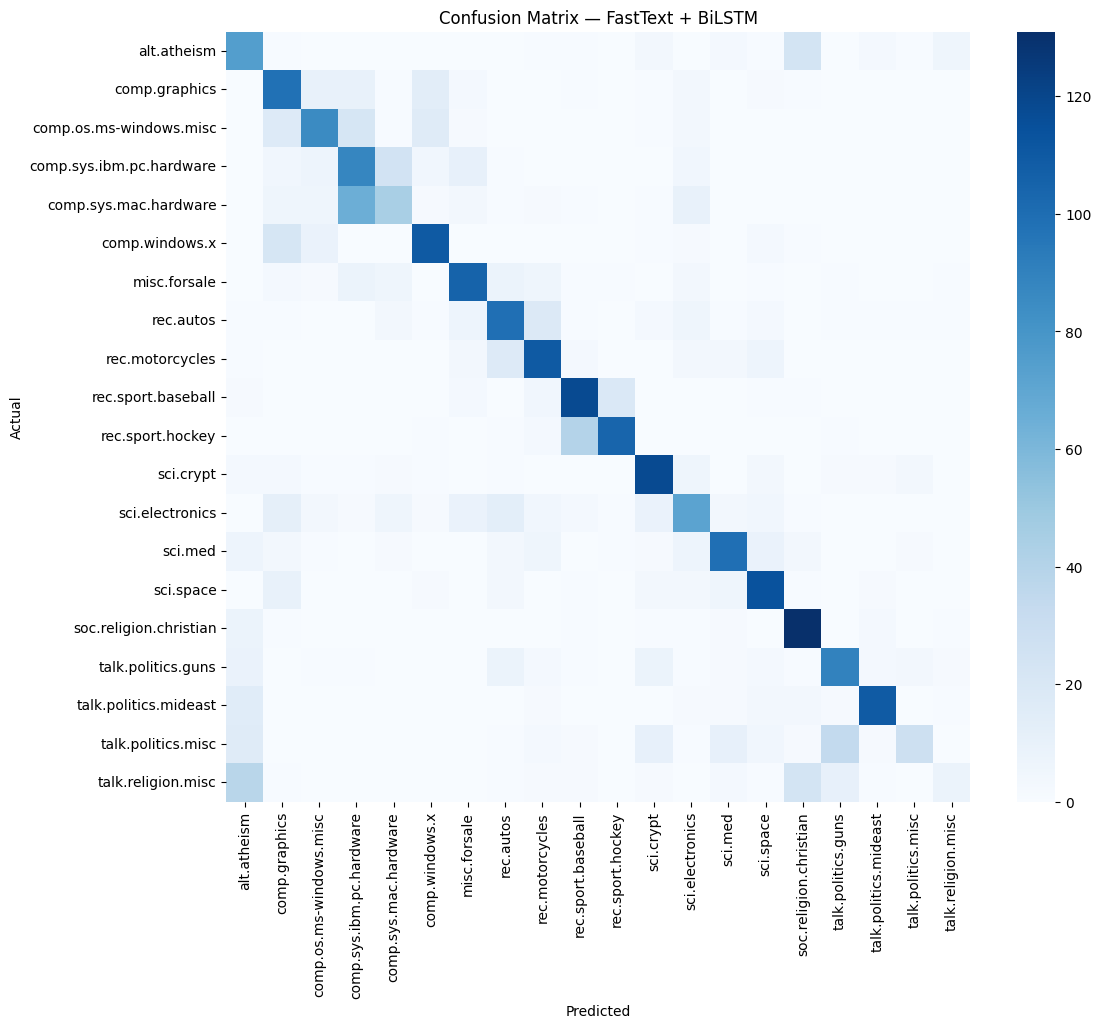


Training FastText + BiGRU
Epoch 1/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 7s 46ms/step - accuracy: 0.1449 - loss: 2.6911 - val_accuracy: 0.3037 - val_loss: 2.0510
Epoch 2/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - accuracy: 0.3387 - loss: 1.8751 - val_accuracy: 0.4584 - val_loss: 1.5397
Epoch 3/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - accuracy: 0.4644 - loss: 1.5258 - val_accuracy: 0.5278 - val_loss: 1.3654
Epoch 4/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.5289 - loss: 1.3447 - val_accuracy: 0.5621 - val_loss: 1.2489
Epoch 5/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - accuracy: 0.5746 - loss: 1.2344 - val_accuracy: 0.5834 - val_loss: 1.2021
Epoch 6/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - accuracy: 0.5953 - loss: 1.1646 - val_accuracy: 0.6085 - val_loss: 1.1383
Epoch 7/7
103/103 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.6217 - loss: 1.0911 - val_accuracy: 0.6159 - val_loss: 1.1153
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step

FastText + BiGRU
Accuracy : 0.642831

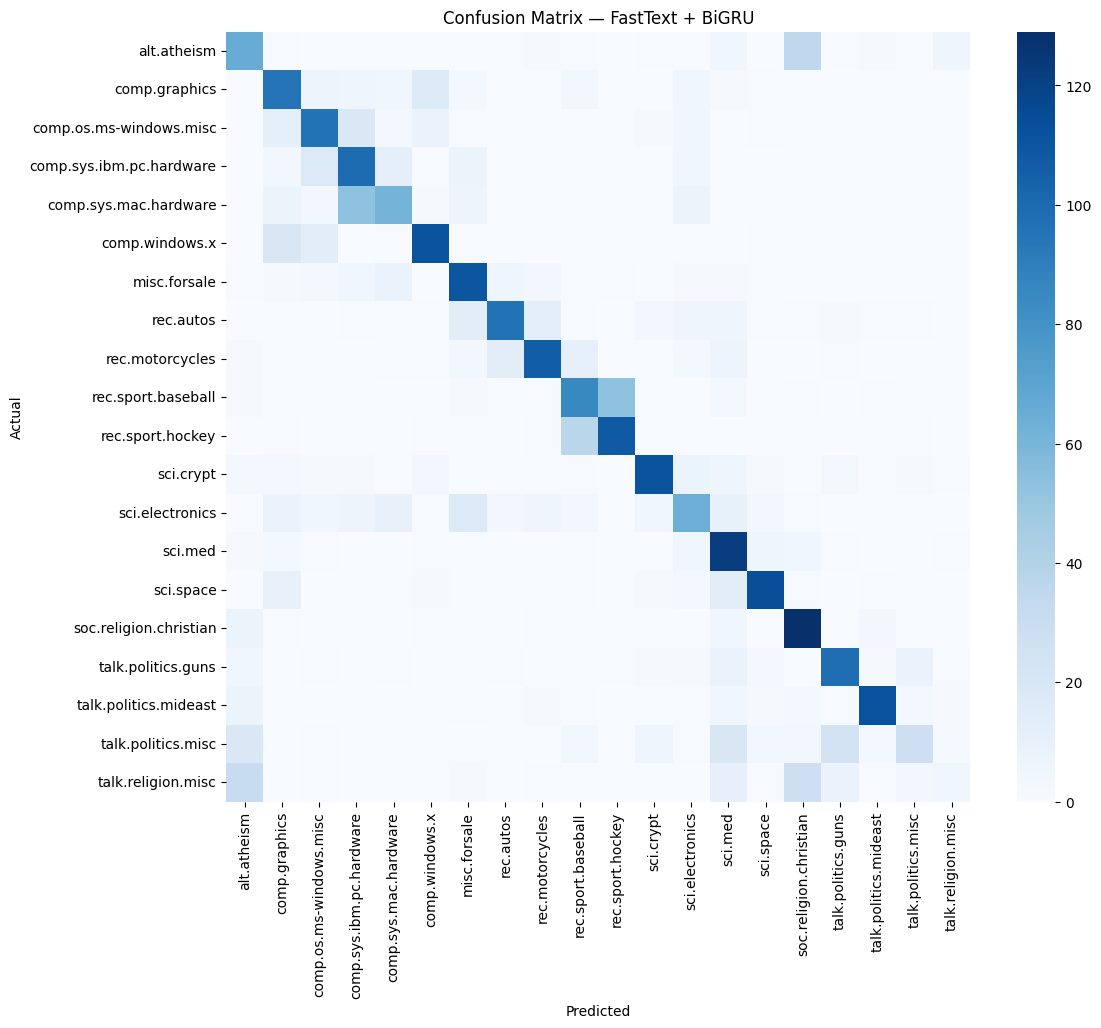

In [33]:
for architecture in RNN_MODELS:

    print(
        "\nTraining FastText +",
        architecture
    )

    model = build_pretrained_embedding_model(
        embedding_matrix_fasttext,
        100,
        architecture=architecture,
        trainable=False
    )

    model.fit(
        X_train_pad,
        y_train,

        validation_data=(
            X_val_pad,
            y_val
        ),

        epochs=7,
        batch_size=128,

        callbacks=[
            EarlyStopping(
                patience=2,
                restore_best_weights=True
            )
        ],

        verbose=1
    )

    probs = model.predict(
        X_test_pad,
        batch_size=128
    )

    pred = np.argmax(
        probs,
        axis=1
    )

    evaluate_model(
        f"FastText + {architecture}",
        y_test,
        pred
    )

In [35]:
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Device:", device)

PyTorch version: 2.11.0+cu128
Device: cuda


In [36]:
BERT_MODEL_NAME = "bert-base-uncased"

bert_tokenizer = AutoTokenizer.from_pretrained(
    BERT_MODEL_NAME
)

In [37]:
BERT_MAX_LEN = 128


bert_train = bert_tokenizer(
    list(X_train_clean),
    padding=True,
    truncation=True,
    max_length=BERT_MAX_LEN
)

bert_val = bert_tokenizer(
    list(X_val_clean),
    padding=True,
    truncation=True,
    max_length=BERT_MAX_LEN
)

bert_test = bert_tokenizer(
    list(X_test_clean),
    padding=True,
    truncation=True,
    max_length=BERT_MAX_LEN
)

print(
    "BERT tokenization completed!"
)

print(
    "Training samples:",
    len(bert_train["input_ids"])
)

BERT tokenization completed!
Training samples: 13184


In [38]:
from torch.utils.data import Dataset, DataLoader


class BERTDataset(Dataset):

    def __init__(
        self,
        encodings,
        labels
    ):

        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):

        item = {
            key: torch.tensor(
                value[idx]
            )
            for key, value in self.encodings.items()
        }

        item["labels"] = torch.tensor(
            self.labels[idx],
            dtype=torch.long
        )

        return item

    def __len__(self):

        return len(self.labels)

In [39]:
train_dataset = BERTDataset(
    bert_train,
    y_train
)

val_dataset = BERTDataset(
    bert_val,
    y_val
)

test_dataset = BERTDataset(
    bert_test,
    y_test
)


BATCH_SIZE = 16


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)


print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 824
Validation batches: 177
Test batches: 177


In [40]:
bert_classifier = AutoModelForSequenceClassification.from_pretrained(
    BERT_MODEL_NAME,
    num_labels=NUM_CLASSES
)

bert_classifier = bert_classifier.to(device)

print("BERT model loaded!")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT model loaded!


In [41]:
optimizer = torch.optim.AdamW(
    bert_classifier.parameters(),
    lr=2e-5
)


def train_bert(
    model,
    train_loader,
    val_loader,
    optimizer,
    epochs=2
):

    for epoch in range(epochs):

        # ==========================
        # TRAIN
        # ==========================

        model.train()

        total_train_loss = 0

        for batch in train_loader:

            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }

            optimizer.zero_grad()

            outputs = model(
                **batch
            )

            loss = outputs.loss

            loss.backward()

            optimizer.step()

            total_train_loss += loss.item()


        # ==========================
        # VALIDATION
        # ==========================

        model.eval()

        total_val_loss = 0

        with torch.no_grad():

            for batch in val_loader:

                batch = {
                    key: value.to(device)
                    for key, value in batch.items()
                }

                outputs = model(
                    **batch
                )

                total_val_loss += outputs.loss.item()


        avg_train_loss = (
            total_train_loss /
            len(train_loader)
        )

        avg_val_loss = (
            total_val_loss /
            len(val_loader)
        )

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train Loss: {avg_train_loss:.4f} | "
            f"Val Loss: {avg_val_loss:.4f}"
        )


train_bert(
    bert_classifier,
    train_loader,
    val_loader,
    optimizer,
    epochs=2
)

Epoch 1/2 | Train Loss: 1.3098 | Val Loss: 0.7792
Epoch 2/2 | Train Loss: 0.5562 | Val Loss: 0.6271



BERT Fine-Tuning
Accuracy : 0.8148672566371682
Precision: 0.8208460756813419
Recall   : 0.8148672566371682
F1 Score : 0.8111070626388477


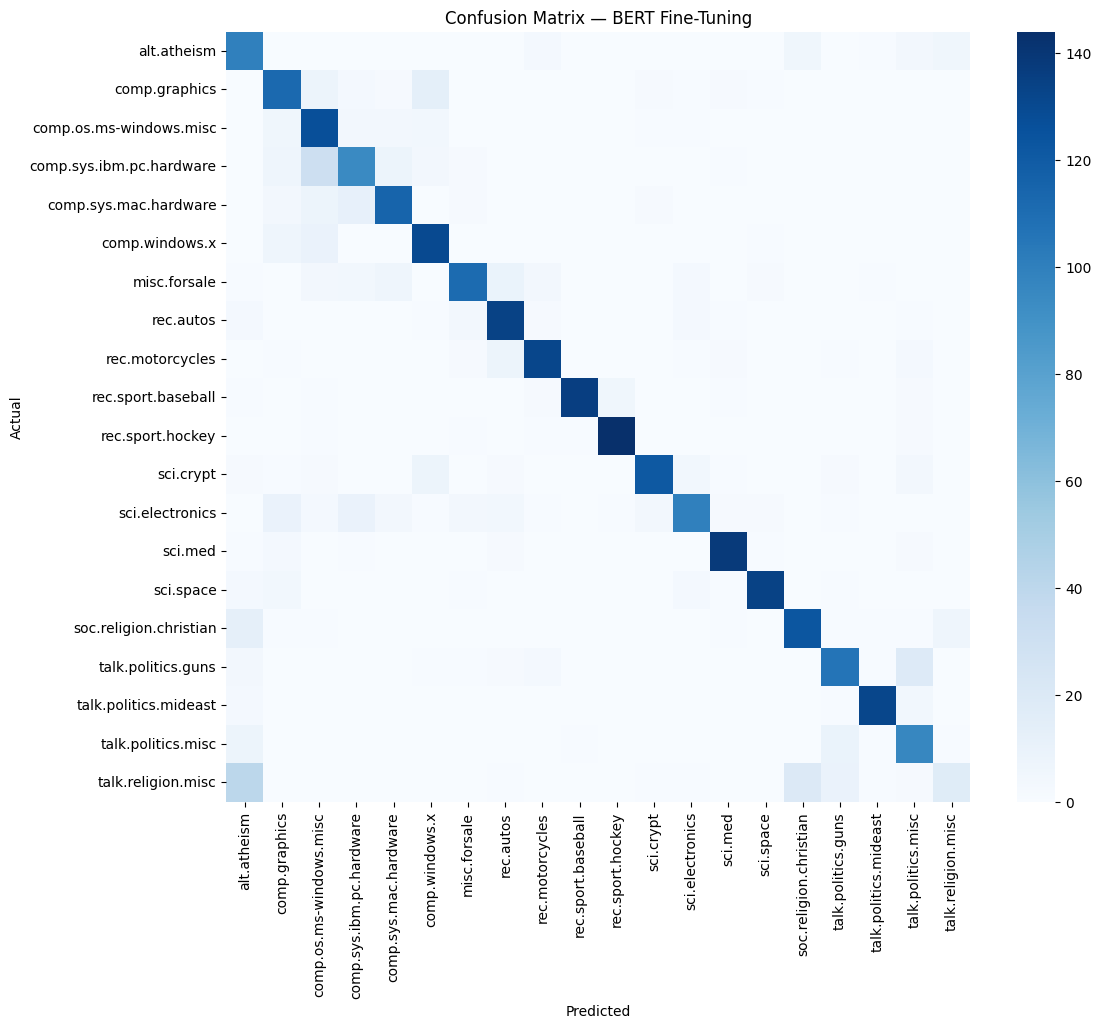

(0.8148672566371682,
 0.8208460756813419,
 0.8148672566371682,
 0.8111070626388477)

In [42]:
bert_classifier.eval()

bert_pred = []
bert_true = []


with torch.no_grad():

    for batch in test_loader:

        labels = batch["labels"]

        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        outputs = bert_classifier(
            **batch
        )

        predictions = torch.argmax(
            outputs.logits,
            dim=1
        )

        bert_pred.extend(
            predictions.cpu().numpy()
        )

        bert_true.extend(
            labels.numpy()
        )


evaluate_model(
    "BERT Fine-Tuning",
    bert_true,
    bert_pred
)

In [43]:
class TransformerEncoder(
    tf.keras.layers.Layer
):

    def __init__(
        self,
        embed_dim,
        num_heads,
        ff_dim,
        dropout=0.1
    ):

        super().__init__()

        self.attention = tf.keras.layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embed_dim
        )

        self.ffn = tf.keras.Sequential([
            Dense(
                ff_dim,
                activation="relu"
            ),

            Dense(
                embed_dim
            )
        ])

        self.layernorm1 = tf.keras.layers.LayerNormalization(
            epsilon=1e-6
        )

        self.layernorm2 = tf.keras.layers.LayerNormalization(
            epsilon=1e-6
        )

        self.dropout1 = Dropout(
            dropout
        )

        self.dropout2 = Dropout(
            dropout
        )

    def call(
        self,
        inputs,
        training=False
    ):

        attention_output = self.attention(
            inputs,
            inputs,
            training=training
        )

        attention_output = self.dropout1(
            attention_output,
            training=training
        )

        out1 = self.layernorm1(
            inputs + attention_output
        )

        ffn_output = self.ffn(
            out1
        )

        ffn_output = self.dropout2(
            ffn_output,
            training=training
        )

        return self.layernorm2(
            out1 + ffn_output
        )

In [44]:
class PositionalEmbedding(
    tf.keras.layers.Layer
):

    def __init__(
        self,
        vocab_size,
        maxlen,
        embed_dim
    ):

        super().__init__()

        self.token_emb = Embedding(
            vocab_size,
            embed_dim
        )

        self.pos_emb = Embedding(
            maxlen,
            embed_dim
        )

        self.maxlen = maxlen

    def call(self, x):

        positions = tf.range(
            start=0,
            limit=tf.shape(x)[-1],
            delta=1
        )

        positions = self.pos_emb(
            positions
        )

        x = self.token_emb(
            x
        )

        return x + positions


In [45]:
transformer_inputs = tf.keras.Input(
    shape=(MAX_LEN,),
    dtype=tf.int32
)

x = PositionalEmbedding(
    VOCAB_SIZE,
    MAX_LEN,
    128
)(transformer_inputs)

x = TransformerEncoder(
    embed_dim=128,
    num_heads=4,
    ff_dim=256
)(x)

x = GlobalAveragePooling1D()(x)

x = Dropout(0.3)(x)

x = Dense(
    128,
    activation="relu"
)(x)

x = Dropout(0.3)(x)

transformer_outputs = Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

transformer_model = tf.keras.Model(
    transformer_inputs,
    transformer_outputs
)

transformer_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

transformer_model.summary()

Model: "functional_23"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_22 (InputLayer)     │ (None, 300)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ positional_embedding            │ (None, 300, 128)       │     3,878,400 │
│ (PositionalEmbedding)           │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_encoder             │ (None, 300, 128)       │       330,240 │
│ (TransformerEncoder)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_44 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_50 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_45 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_51 (Dense)                │ (None, 20)             │         2,580 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,227,732 (16.13 MB)

 Trainable params: 4,227,732 (16.13 MB)

 Non-trainable params: 0 (0.00 B)

In [46]:
transformer_model.fit(

    X_train_pad,
    y_train,

    validation_data=(
        X_val_pad,
        y_val
    ),

    epochs=8,
    batch_size=128,

    callbacks=[
        EarlyStopping(
            patience=2,
            restore_best_weights=True
        )
    ]
)

Epoch 1/8
103/103 ━━━━━━━━━━━━━━━━━━━━ 21s 97ms/step - accuracy: 0.0894 - loss: 2.9374 - val_accuracy: 0.2096 - val_loss: 2.4781
Epoch 2/8
103/103 ━━━━━━━━━━━━━━━━━━━━ 8s 75ms/step - accuracy: 0.5601 - loss: 1.3885 - val_accuracy: 0.7858 - val_loss: 0.7133
Epoch 3/8
103/103 ━━━━━━━━━━━━━━━━━━━━ 8s 77ms/step - accuracy: 0.8739 - loss: 0.4423 - val_accuracy: 0.8432 - val_loss: 0.6292
Epoch 4/8
103/103 ━━━━━━━━━━━━━━━━━━━━ 8s 78ms/step - accuracy: 0.9483 - loss: 0.1888 - val_accuracy: 0.8453 - val_loss: 0.6765
Epoch 5/8
103/103 ━━━━━━━━━━━━━━━━━━━━ 8s 77ms/step - accuracy: 0.9757 - loss: 0.0916 - val_accuracy: 0.8457 - val_loss: 0.8121


23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 75ms/step
Predictions created!
Prediction shape: (2825,)

Transformer Encoder
Accuracy : 0.8569911504424779
Precision: 0.8616786453625552
Recall   : 0.8569911504424779
F1 Score : 0.8572977504218


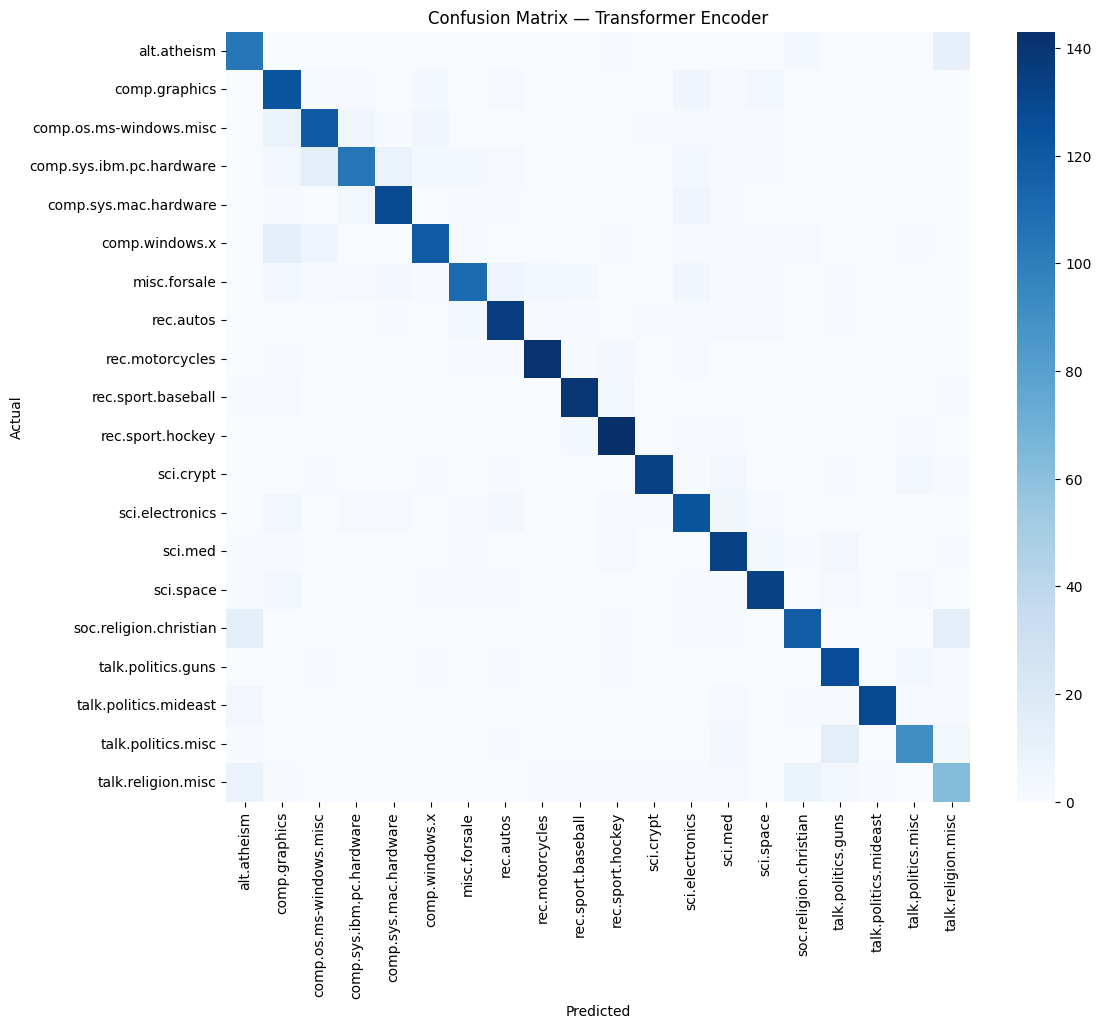

(0.8569911504424779, 0.8616786453625552, 0.8569911504424779, 0.8572977504218)

In [65]:


transformer_probs = transformer_model.predict(
    X_test_pad,
    batch_size=128,
    verbose=1
)

transformer_pred = np.argmax(
    transformer_probs,
    axis=1
)

print("Predictions created!")
print("Prediction shape:", transformer_pred.shape)

evaluate_model(
    "Transformer Encoder",
    y_test,
    transformer_pred
)

In [67]:
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM
)

LLM_NAME = "google/flan-t5-base"

llm_tokenizer = AutoTokenizer.from_pretrained(
    LLM_NAME
)

llm_model = AutoModelForSeq2SeqLM.from_pretrained(
    LLM_NAME
)

DEVICE = "cuda" if tf.config.list_physical_devices("GPU") else "cpu"

import torch

llm_model = llm_model.to(
    DEVICE
)

print("LLM device:", DEVICE)

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


LLM device: cuda


In [68]:
LABEL_TEXT = "\n".join([
    f"{i}: {name}"
    for i, name in enumerate(CLASS_NAMES)
])

print(LABEL_TEXT)


0: alt.atheism
1: comp.graphics
2: comp.os.ms-windows.misc
3: comp.sys.ibm.pc.hardware
4: comp.sys.mac.hardware
5: comp.windows.x
6: misc.forsale
7: rec.autos
8: rec.motorcycles
9: rec.sport.baseball
10: rec.sport.hockey
11: sci.crypt
12: sci.electronics
13: sci.med
14: sci.space
15: soc.religion.christian
16: talk.politics.guns
17: talk.politics.mideast
18: talk.politics.misc
19: talk.religion.misc


In [69]:
def llm_predict(
    text,
    examples=None
):

    if examples is None:

        prompt = f"""
Classify the following newsgroup document into exactly
one of these categories.

Categories:
{LABEL_TEXT}

Document:
{text}

Return only the category number.
"""

    else:

        example_text = ""

        for example_doc, example_label in examples:

            example_text += f"""
Example:
Document: {example_doc}
Category: {example_label}
"""

        prompt = f"""
Classify the following newsgroup document.

Possible categories:
{LABEL_TEXT}

{example_text}

Document:
{text}

Return only the category number.
"""

    inputs = llm_tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    )

    inputs = {
        key: value.to(DEVICE)
        for key, value in inputs.items()
    }

    with torch.no_grad():

        outputs = llm_model.generate(
            **inputs,
            max_new_tokens=10
        )

    answer = llm_tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    match = re.search(
        r'\b([0-9]|1[0-9])\b',
        answer
    )

    if match:

        value = int(
            match.group(1)
        )

        if 0 <= value < NUM_CLASSES:
            return value

    return -1

In [70]:
LLM_TEST_SIZE = min(
    500,
    len(X_test_clean)
)

llm_test_texts = X_test_clean[
    :LLM_TEST_SIZE
]

llm_test_labels = y_test[
    :LLM_TEST_SIZE
]


Processed: 25 / 500
Processed: 50 / 500
Processed: 75 / 500
Processed: 100 / 500
Processed: 125 / 500
Processed: 150 / 500
Processed: 175 / 500
Processed: 200 / 500
Processed: 225 / 500
Processed: 250 / 500
Processed: 275 / 500
Processed: 300 / 500
Processed: 325 / 500
Processed: 350 / 500
Processed: 375 / 500
Processed: 400 / 500
Processed: 425 / 500
Processed: 450 / 500
Processed: 475 / 500
Processed: 500 / 500

LLM Zero-Shot
Accuracy : 0.2857142857142857
Precision: 0.3599695636372764
Recall   : 0.2857142857142857
F1 Score : 0.24756455068181343


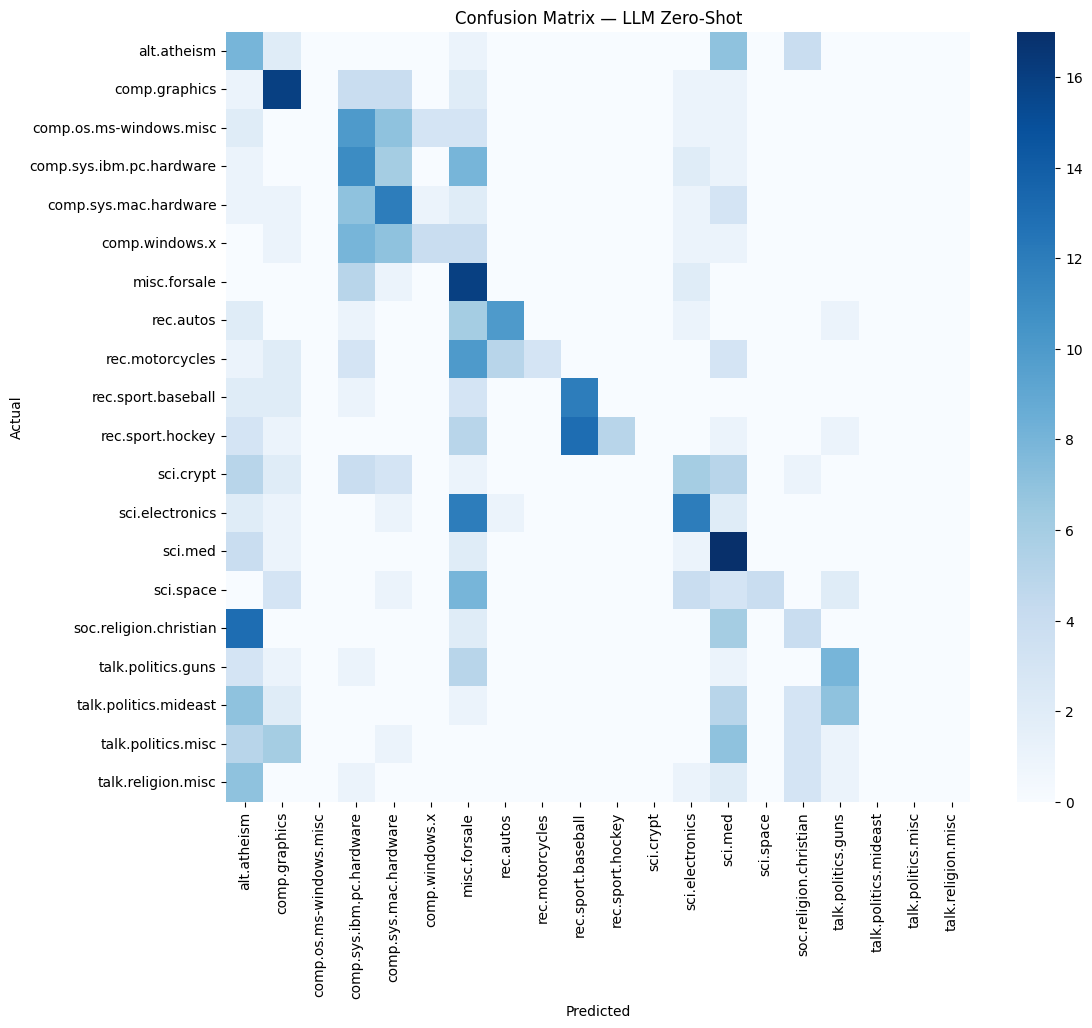

(0.2857142857142857,
 0.3599695636372764,
 0.2857142857142857,
 0.24756455068181343)

In [71]:
zero_shot_predictions = []

for i, text in enumerate(
    llm_test_texts
):

    prediction = llm_predict(
        text
    )

    zero_shot_predictions.append(
        prediction
    )

    if (i + 1) % 25 == 0:

        print(
            "Processed:",
            i + 1,
            "/",
            LLM_TEST_SIZE
        )


# Remove invalid predictions

valid_mask = np.array(
    zero_shot_predictions
) != -1

zero_true = np.array(
    llm_test_labels
)[valid_mask]

zero_pred = np.array(
    zero_shot_predictions
)[valid_mask]

evaluate_model(
    "LLM Zero-Shot",
    zero_true,
    zero_pred
)


In [72]:
one_shot_examples = []

for class_id in range(NUM_CLASSES):

    indices = np.where(
        y_train == class_id
    )[0]

    if len(indices) > 0:

        idx = indices[0]

        one_shot_examples.append(
            (
                X_train_clean[idx],
                class_id
            )
        )

print(
    "One-shot examples:",
    len(one_shot_examples)
)




One-shot examples: 20


Processed: 25 / 500
Processed: 50 / 500
Processed: 75 / 500
Processed: 100 / 500
Processed: 125 / 500
Processed: 150 / 500
Processed: 175 / 500
Processed: 200 / 500
Processed: 225 / 500
Processed: 250 / 500
Processed: 275 / 500
Processed: 300 / 500
Processed: 325 / 500
Processed: 350 / 500
Processed: 375 / 500
Processed: 400 / 500
Processed: 425 / 500
Processed: 450 / 500
Processed: 475 / 500
Processed: 500 / 500

LLM One-Shot
Accuracy : 0.044
Precision: 0.001936
Recall   : 0.044
F1 Score : 0.0037088122605363986


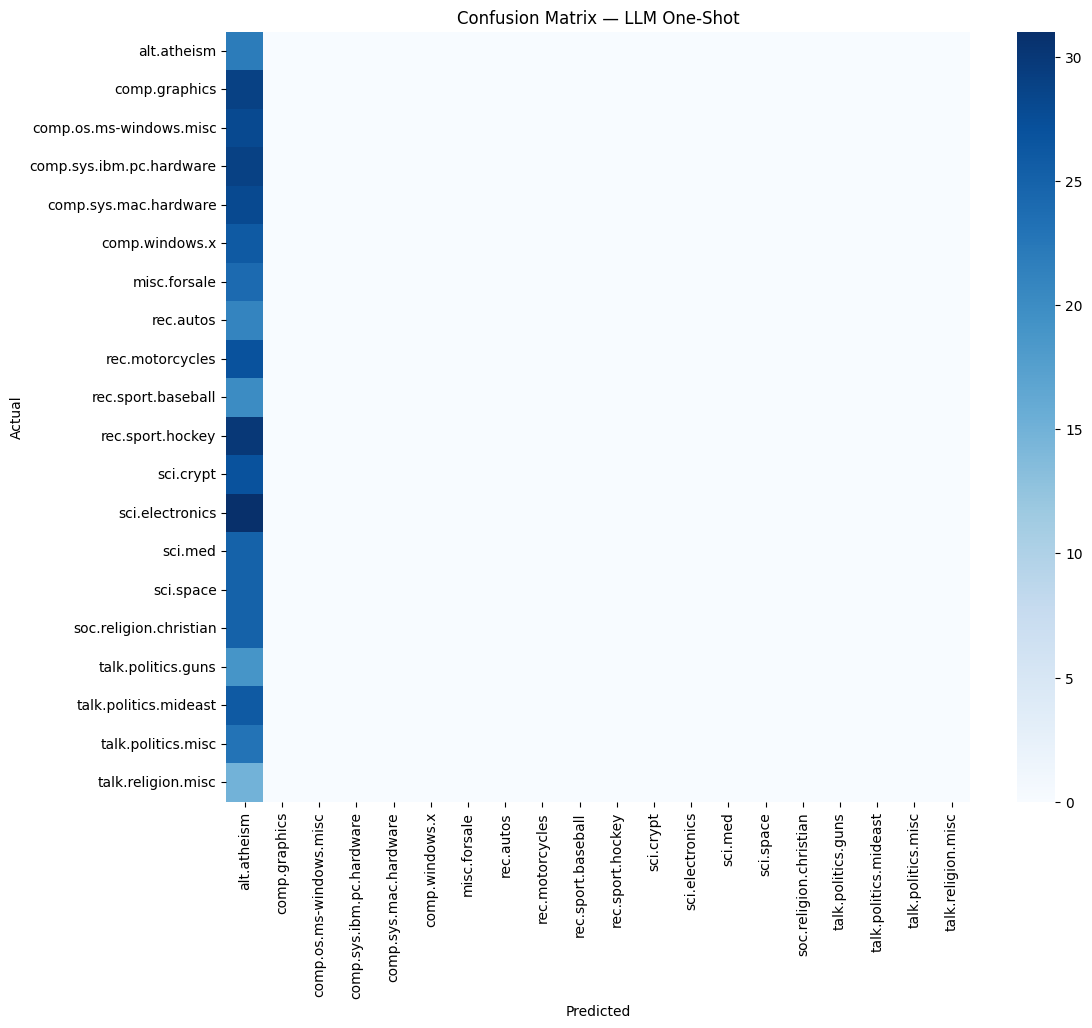

(0.044, 0.001936, 0.044, 0.0037088122605363986)

In [73]:


one_shot_predictions = []

for i, text in enumerate(
    llm_test_texts
):

    prediction = llm_predict(
        text,
        examples=one_shot_examples
    )

    one_shot_predictions.append(
        prediction
    )

    if (i + 1) % 25 == 0:

        print(
            "Processed:",
            i + 1,
            "/",
            LLM_TEST_SIZE
        )


valid_mask = np.array(
    one_shot_predictions
) != -1

one_true = np.array(
    llm_test_labels
)[valid_mask]

one_pred = np.array(
    one_shot_predictions
)[valid_mask]

evaluate_model(
    "LLM One-Shot",
    one_true,
    one_pred
)

In [74]:
FEW_SHOT_PER_CLASS = 5

few_shot_examples = []

for class_id in range(NUM_CLASSES):

    indices = np.where(
        y_train == class_id
    )[0]

    selected = indices[
        :FEW_SHOT_PER_CLASS
    ]

    for idx in selected:

        few_shot_examples.append(
            (
                X_train_clean[idx],
                class_id
            )
        )

print(
    "Few-shot examples:",
    len(few_shot_examples)
)


Few-shot examples: 100


Processed: 25 / 500
Processed: 50 / 500
Processed: 75 / 500
Processed: 100 / 500
Processed: 125 / 500
Processed: 150 / 500
Processed: 175 / 500
Processed: 200 / 500
Processed: 225 / 500
Processed: 250 / 500
Processed: 275 / 500
Processed: 300 / 500
Processed: 325 / 500
Processed: 350 / 500
Processed: 375 / 500
Processed: 400 / 500
Processed: 425 / 500
Processed: 450 / 500
Processed: 475 / 500
Processed: 500 / 500

LLM Few-Shot
Accuracy : 0.044
Precision: 0.001936
Recall   : 0.044
F1 Score : 0.0037088122605363986


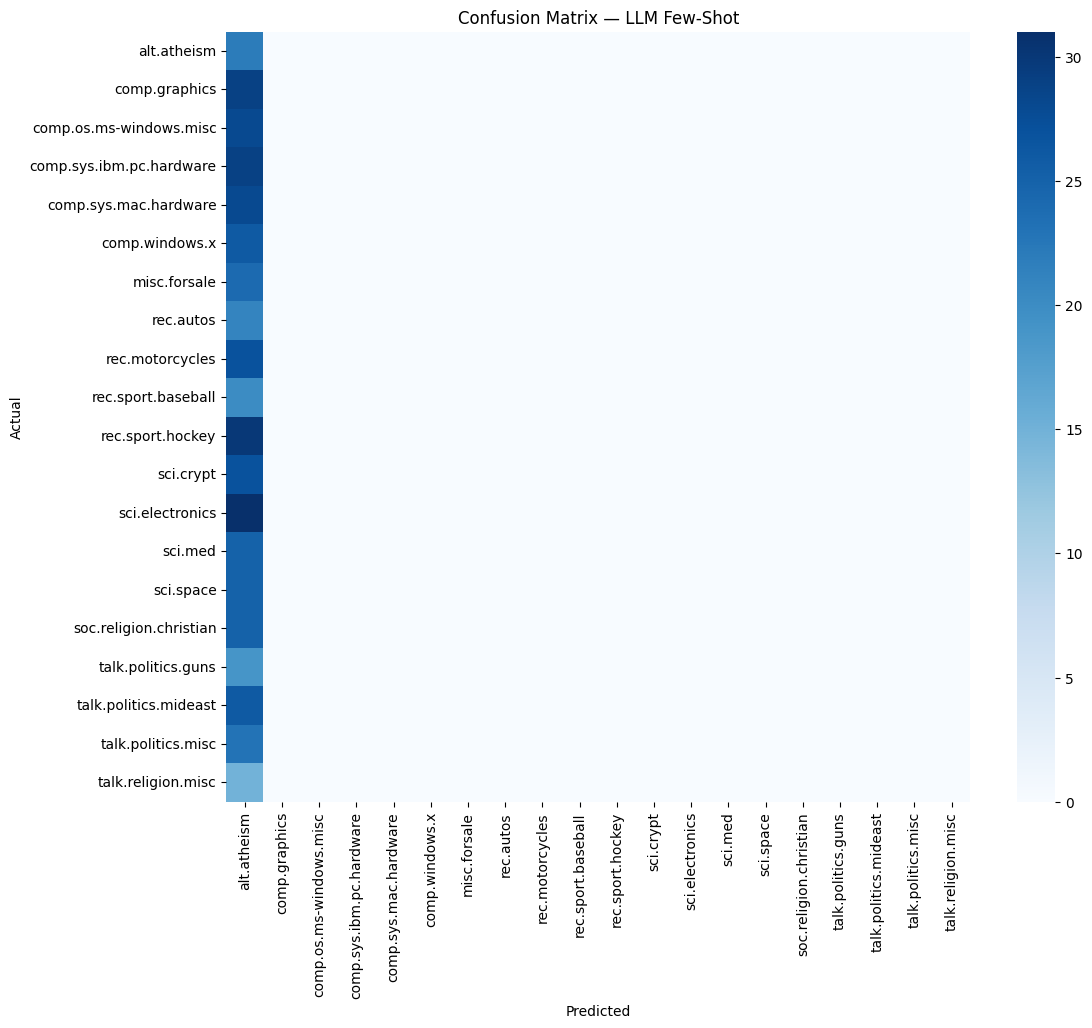

(0.044, 0.001936, 0.044, 0.0037088122605363986)

In [75]:
few_shot_predictions = []

for i, text in enumerate(
    llm_test_texts
):

    prediction = llm_predict(
        text,
        examples=few_shot_examples
    )

    few_shot_predictions.append(
        prediction
    )

    if (i + 1) % 25 == 0:

        print(
            "Processed:",
            i + 1,
            "/",
            LLM_TEST_SIZE
        )


valid_mask = np.array(
    few_shot_predictions
) != -1

few_true = np.array(
    llm_test_labels
)[valid_mask]

few_pred = np.array(
    few_shot_predictions
)[valid_mask]

evaluate_model(
    "LLM Few-Shot",
    few_true,
    few_pred
)


In [76]:
results_df = pd.DataFrame(
    RESULTS
)

results_df = results_df.sort_values(
    by="F1",
    ascending=False
)

results_df

,Model,Accuracy,Precision,Recall,F1
0,ANN + TF-IDF,0.878938,0.880887,0.878938,0.879240
2,CNN kernel=5,0.865487,0.866952,0.865487,0.865405
3,CNN kernel=7,0.859823,0.864617,0.859823,0.860864
1,CNN kernel=3,0.860177,0.863034,0.860177,0.860672
26,Transformer Encoder,0.856991,0.861679,0.856991,0.857298
22,BERT Fine-Tuning,0.814867,0.820846,0.814867,0.811107
7,BiLSTM,0.798938,0.818197,0.798938,0.803427
8,BiGRU,0.729558,0.744801,0.729558,0.732976
16,Word2Vec + BiGRU,0.702655,0.715590,0.702655,0.693790
15,Word2Vec + BiLSTM,0.690619,0.698948,0.690619,0.681699


In [77]:
results_df.to_csv(
    "nlp_assignment_results.csv",
    index=False
)

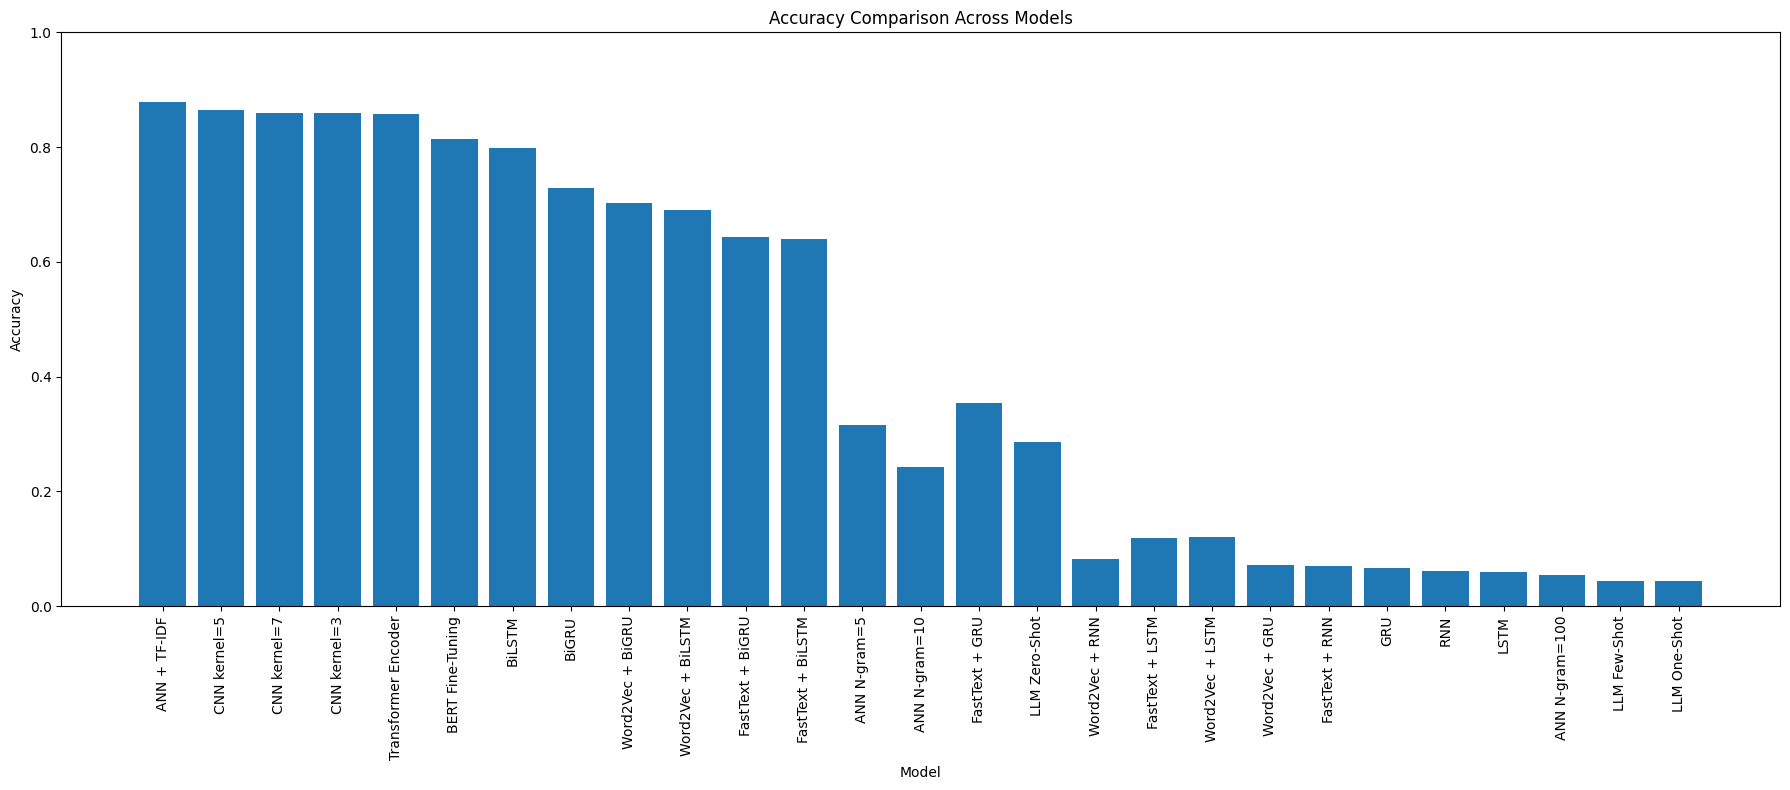

In [78]:
plt.figure(
    figsize=(18, 8)
)

plt.bar(
    results_df["Model"],
    results_df["Accuracy"]
)

plt.xticks(
    rotation=90
)

plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.title(
    "Accuracy Comparison Across Models"
)

plt.ylim(
    0,
    1
)

plt.tight_layout()
plt.show()

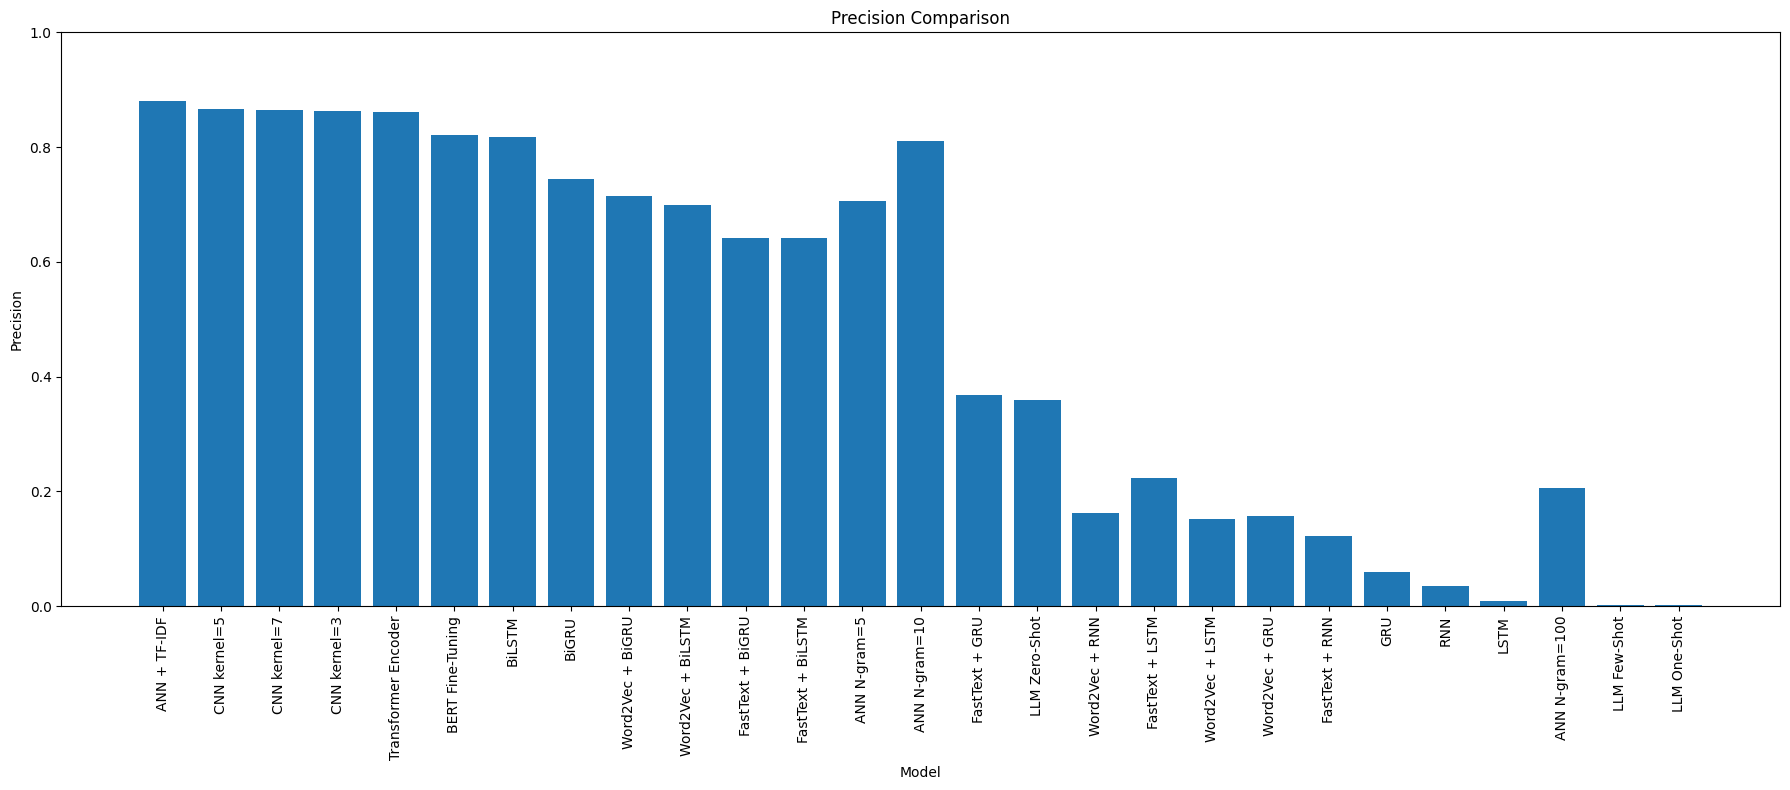

In [79]:
plt.figure(
    figsize=(18, 8)
)

plt.bar(
    results_df["Model"],
    results_df["Precision"]
)

plt.xticks(
    rotation=90
)

plt.ylabel("Precision")
plt.xlabel("Model")
plt.title(
    "Precision Comparison"
)

plt.ylim(
    0,
    1
)

plt.tight_layout()
plt.show()

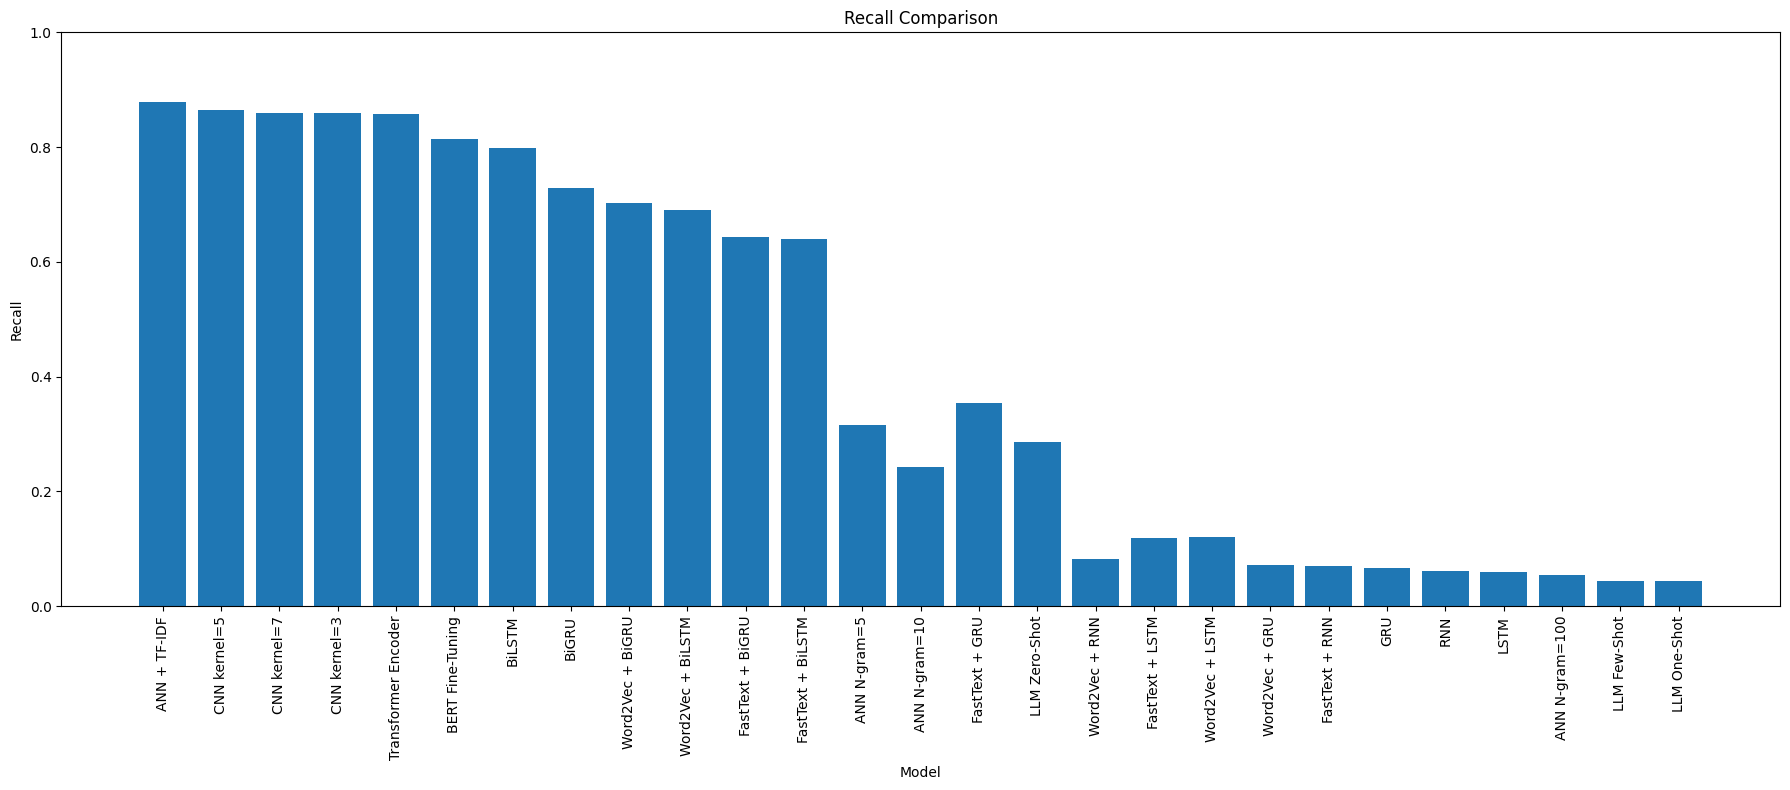

In [80]:
plt.figure(
    figsize=(18, 8)
)

plt.bar(
    results_df["Model"],
    results_df["Recall"]
)

plt.xticks(
    rotation=90
)

plt.ylabel("Recall")
plt.xlabel("Model")
plt.title(
    "Recall Comparison"
)

plt.ylim(
    0,
    1
)

plt.tight_layout()
plt.show()


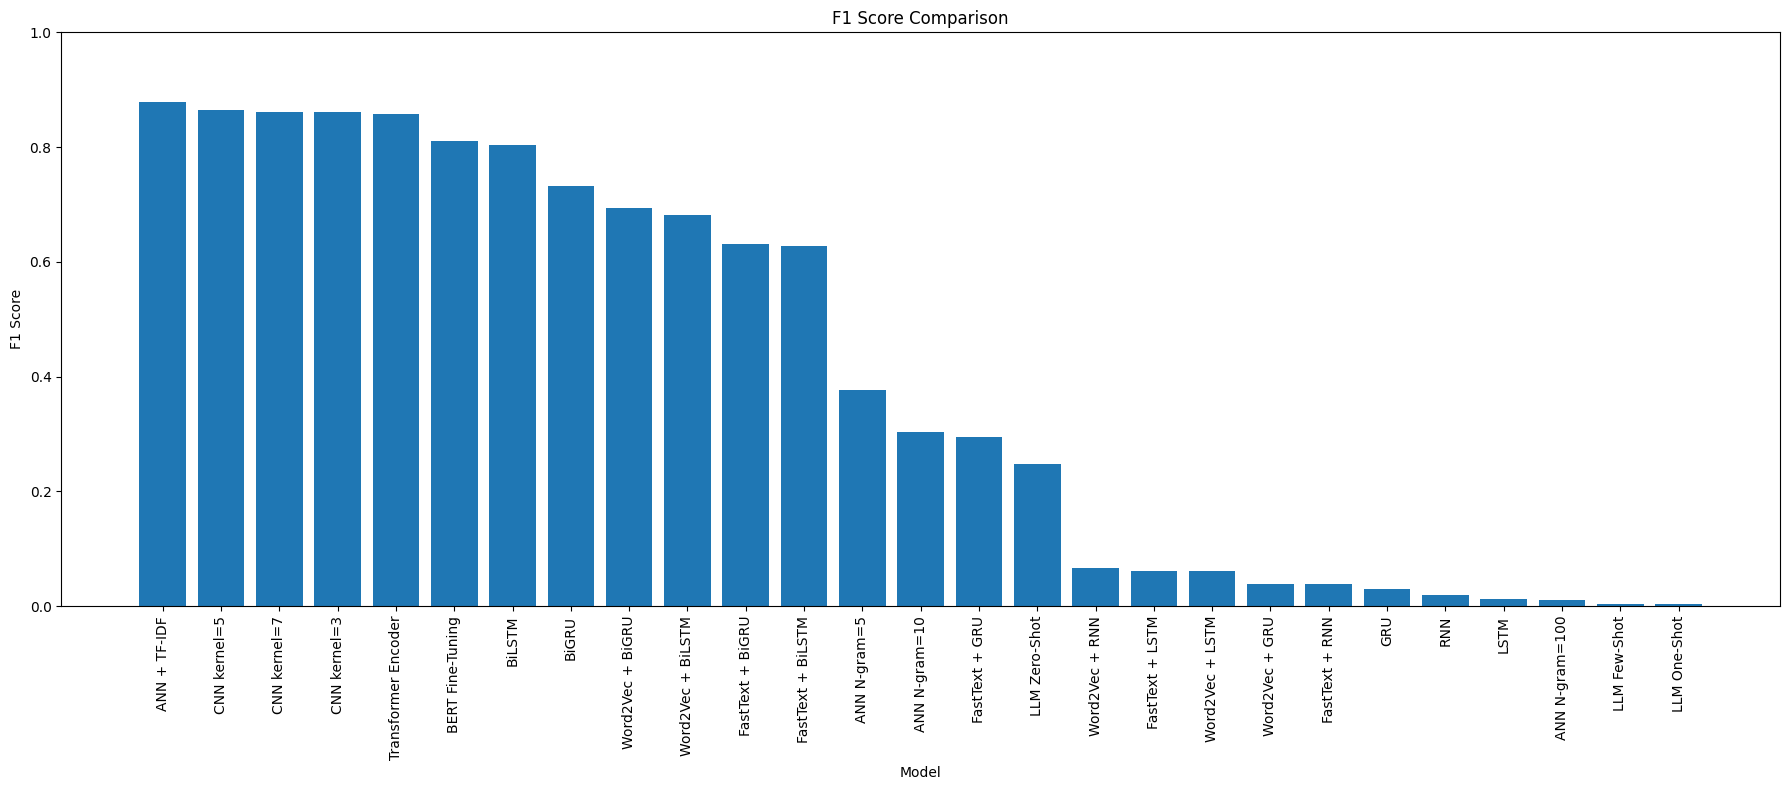

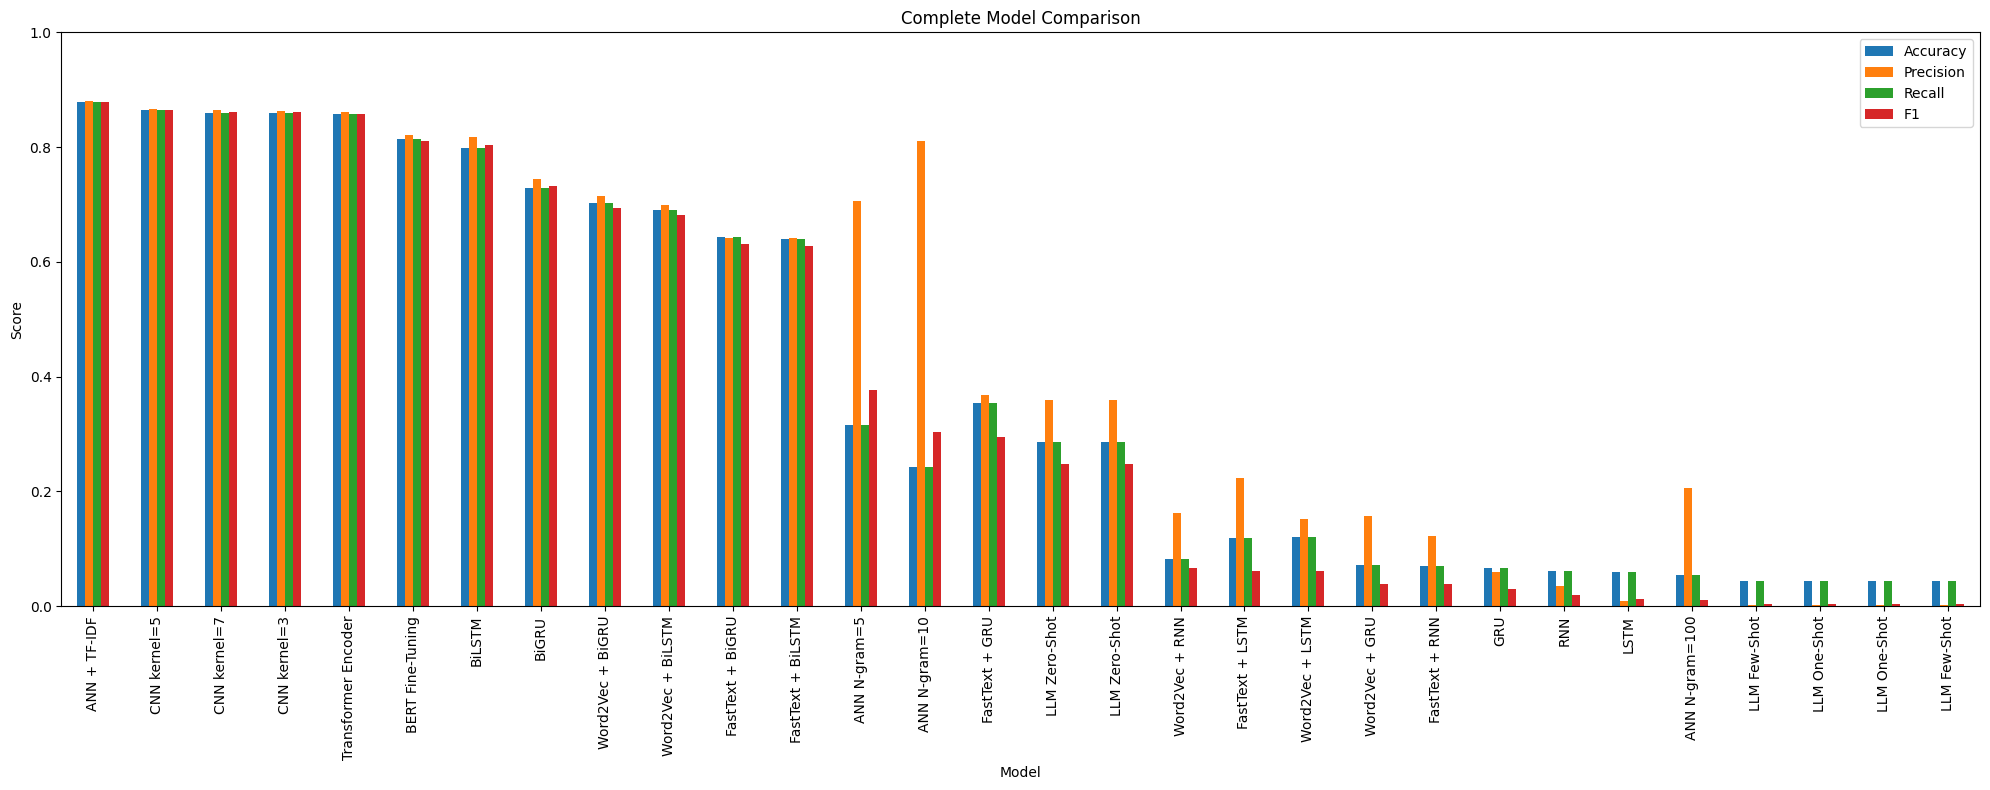

In [81]:
plt.figure(
    figsize=(18, 8)
)

plt.bar(
    results_df["Model"],
    results_df["F1"]
)

plt.xticks(
    rotation=90
)

plt.ylabel("F1 Score")
plt.xlabel("Model")
plt.title(
    "F1 Score Comparison"
)

plt.ylim(
    0,
    1
)

plt.tight_layout()
plt.show()


plot_df = results_df.set_index(
    "Model"
)[
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1"
    ]
]

plot_df.plot(
    kind="bar",
    figsize=(20, 8)
)

plt.ylabel("Score")
plt.xlabel("Model")
plt.title(
    "Complete Model Comparison"
)

plt.ylim(
    0,
    1
)

plt.xticks(
    rotation=90
)

plt.tight_layout()
plt.show()


In [82]:

print(
    results_df[
        [
            "Model",
            "Accuracy",
            "Precision",
            "Recall",
            "F1"
        ]
    ].to_string(
        index=False
    )
)

              Model  Accuracy  Precision   Recall       F1
       ANN + TF-IDF  0.878938   0.880887 0.878938 0.879240
       CNN kernel=5  0.865487   0.866952 0.865487 0.865405
       CNN kernel=7  0.859823   0.864617 0.859823 0.860864
       CNN kernel=3  0.860177   0.863034 0.860177 0.860672
Transformer Encoder  0.856991   0.861679 0.856991 0.857298
   BERT Fine-Tuning  0.814867   0.820846 0.814867 0.811107
             BiLSTM  0.798938   0.818197 0.798938 0.803427
              BiGRU  0.729558   0.744801 0.729558 0.732976
   Word2Vec + BiGRU  0.702655   0.715590 0.702655 0.693790
  Word2Vec + BiLSTM  0.690619   0.698948 0.690619 0.681699
   FastText + BiGRU  0.642832   0.642252 0.642832 0.631495
  FastText + BiLSTM  0.639292   0.641940 0.639292 0.627732
       ANN N-gram=5  0.316106   0.706893 0.316106 0.376723
      ANN N-gram=10  0.241770   0.810840 0.241770 0.302560
     FastText + GRU  0.353982   0.367857 0.353982 0.295477
      LLM Zero-Shot  0.285714   0.359970 0.285714 0.2475

In [83]:
print(
    classification_report(
        y_test,
        transformer_pred,
        target_names=CLASS_NAMES,
        zero_division=0
    )
)

                          precision    recall  f1-score   support

             alt.atheism       0.78      0.87      0.82       120
           comp.graphics       0.72      0.85      0.78       145
 comp.os.ms-windows.misc       0.82      0.81      0.82       148
comp.sys.ibm.pc.hardware       0.87      0.71      0.78       147
   comp.sys.mac.hardware       0.88      0.90      0.89       143
          comp.windows.x       0.88      0.80      0.84       148
            misc.forsale       0.90      0.76      0.82       147
               rec.autos       0.87      0.91      0.89       149
         rec.motorcycles       0.95      0.94      0.95       150
      rec.sport.baseball       0.94      0.94      0.94       149
        rec.sport.hockey       0.89      0.95      0.92       150
               sci.crypt       0.97      0.90      0.93       148
         sci.electronics       0.77      0.83      0.80       148
                 sci.med       0.81      0.91      0.86       148
         

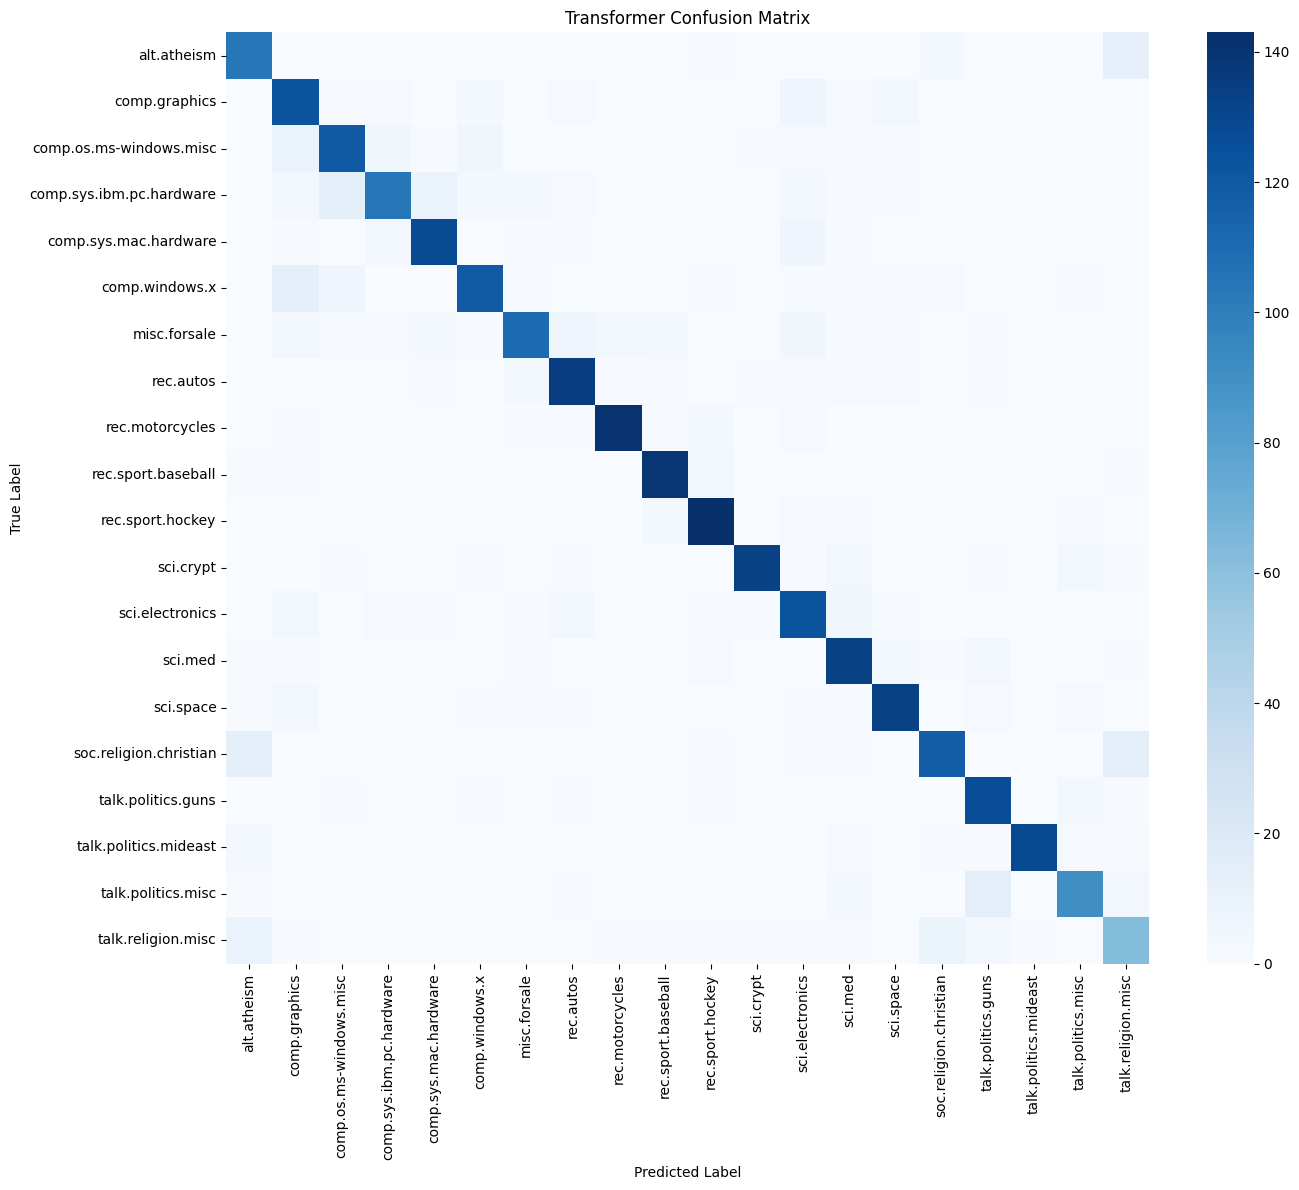

In [84]:
cm = confusion_matrix(
    y_test,
    transformer_pred
)

plt.figure(
    figsize=(14, 12)
)

sns.heatmap(
    cm,
    annot=False,
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "True Label"
)

plt.title(
    "Transformer Confusion Matrix"
)

plt.xticks(
    rotation=90
)

plt.yticks(
    rotation=0
)

plt.tight_layout()
plt.show()


In [85]:
llm_rows = results_df[
    results_df["Model"].str.contains(
        "LLM"
    )
]

llm_rows

,Model,Accuracy,Precision,Recall,F1
27,LLM Zero-Shot,0.285714,0.359970,0.285714,0.247565
23,LLM Zero-Shot,0.285714,0.359970,0.285714,0.247565
25,LLM Few-Shot,0.044000,0.001936,0.044000,0.003709
24,LLM One-Shot,0.044000,0.001936,0.044000,0.003709
28,LLM One-Shot,0.044000,0.001936,0.044000,0.003709
29,LLM Few-Shot,0.044000,0.001936,0.044000,0.003709


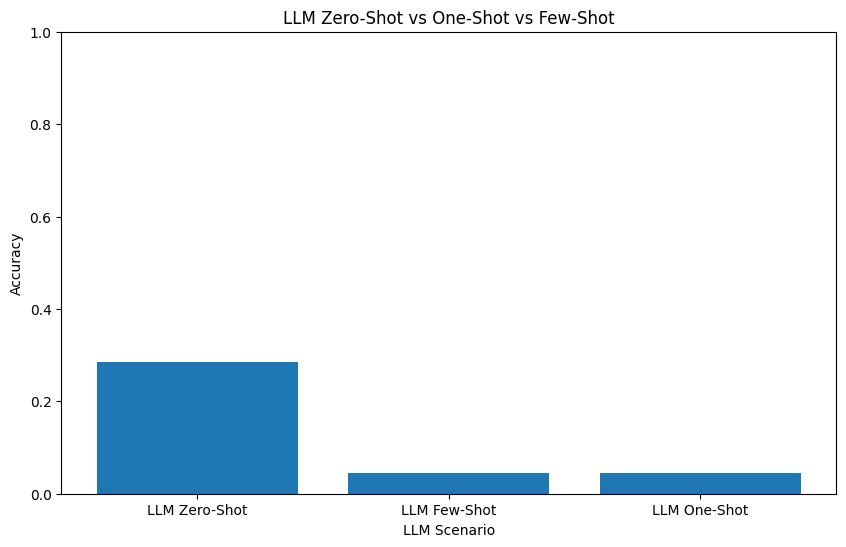

Important preprocessing objects saved.


In [86]:
if len(llm_rows) > 0:

    plt.figure(
        figsize=(10, 6)
    )

    plt.bar(
        llm_rows["Model"],
        llm_rows["Accuracy"]
    )

    plt.ylabel(
        "Accuracy"
    )

    plt.xlabel(
        "LLM Scenario"
    )

    plt.title(
        "LLM Zero-Shot vs One-Shot vs Few-Shot"
    )

    plt.ylim(
        0,
        1
    )

    plt.show()



import pickle

with open(
    "tfidf_vectorizer.pkl",
    "wb"
) as f:

    pickle.dump(
        tfidf,
        f
    )

with open(
    "tokenizer.pkl",
    "wb"
) as f:

    pickle.dump(
        tokenizer,
        f
    )

print(
    "Important preprocessing objects saved."
)
